# Biological Plausibility: Candidate Matching

- **Purpose:** Whole cell line candidate matching plus the joint-model biological plausibility views.
- **Inputs:** Shared artifact `adata_config10_joint/config10_joint_3k.h5ad`; config-10 joint model; cleaned Hallmark GMT; cached DE, GSEA, and MLM results when present.
- **Outputs:** `figures/BIOVAL/` matching and concordance figures; per-subpopulation DE, GSEA, and MLM caches under `models/validation/bio_joint_cfg10/`.
- **Result:** Nine of ten cell lines have `tumor_4` or `tumor_5` as their primary latent match; the pathway analyses support five candidates and leave three unresolved.


Takes the frozen combined artifact from `3_Bio_Clustering_Selection.ipynb`.
The notebook defines tumor-only matching groups, nominates whole-cell-line candidate
matches from tumor-only kNN composition, and characterizes the tumor subpopulations
with model-based differential expression and Hallmark preranked GSEA.

The kNN composition is the primary matching rule. Latent distances are supporting
views, not additional rules. Proximity is a necessary condition for a match, not proof of one.


In [1]:
from pathlib import Path
import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import hashlib
from sklearn.neighbors import NearestNeighbors

import json
import sys
import scvi

SEED = 0
def set_seed(seed):
    scvi.settings.seed = seed
    #torch.manual_seed(seed)
    np.random.seed(seed)
set_seed(SEED)

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
FIG_DIR = ROOT / "figures" / "BIOVAL"
FIG_DIR.mkdir(parents=True, exist_ok=True)

from src.utils import load_config


INPUT = Path.cwd() / "adata_config10_joint" / "config10_joint_3k.h5ad"

K_MATCHING = 50
MIN_LINE_SUBGROUP_CELLS = 50
def tumor_group_sort_key(group):
    return int(str(group).rsplit("_", 1)[-1])


combined_full = ad.read_h5ad(INPUT)
settings = combined_full.uns["bio_leiden_settings"]
TUMOR_RES = float(settings["tumor_res"])
FULL_RES = float(settings["full_res"])
LEIDEN_SEED = int(settings["leiden_seed"])
t_key = f"tumor_leiden_res{TUMOR_RES}"
f_key = f"full_leiden_res{FULL_RES}"

print(f"Input: {INPUT}")
print(f"Shape: {combined_full.shape}")
print(f"Frozen settings: graph_seed={settings['graph_seed']}, leiden_seed={LEIDEN_SEED}, tumor_res={TUMOR_RES}, full_res={FULL_RES}")
print(f"Tumor clusters ({t_key}): {combined_full.obs[t_key].nunique(dropna=True)}")
print(f"Cell lines: {combined_full.obs.loc[combined_full.obs['dataset'].eq('cell_line'), 'cell_line'].nunique()}")

Seed set to 0


Input: /mnt/bigdisk/markus/CRC-scMFmap/notebooks/curr/adata_config10_joint/config10_joint_3k.h5ad
Shape: (110293, 28617)
Frozen settings: graph_seed=0, leiden_seed=3, tumor_res=0.9, full_res=1.0
Tumor clusters (tumor_leiden_res0.9): 18
Cell lines: 10


# Matching Groups
Each cell is in a matching group (for now maybe later not every cell line cell is part of a group due to heterogeneity etc.).

Tumor cells are part of the tumor-only Leiden subpopulation, cell line cells are part of their line.

The kNN search for the cell line cells is **only** on tumor cells. 

In [2]:
tumor_mask = combined_full.obs["dataset"].eq("tumor")
line_mask = combined_full.obs["dataset"].eq("cell_line")

match_group = pd.Series(pd.NA, index=combined_full.obs.index, dtype="string", name="match_group")
match_group.loc[tumor_mask] = "tumor_" + combined_full.obs.loc[tumor_mask, t_key].astype("string")
match_group.loc[line_mask] = "line_" + combined_full.obs.loc[line_mask, "cell_line"].astype("string")
combined_full.obs["match_group"] = match_group

combined_full.obs["match_group"].value_counts()

match_group
tumor_0         12126
tumor_8         11922
tumor_5         11858
tumor_4         11847
tumor_1         10323
tumor_10         8621
tumor_7          7357
tumor_12         7351
tumor_3          7047
tumor_11         4903
tumor_9          4291
tumor_2          3276
tumor_15         1588
tumor_16         1472
tumor_6          1461
tumor_13         1200
tumor_14          836
tumor_17          652
line_SNUC4        471
line_CL34         418
line_LS180        362
line_HT55         211
line_LS1034       153
line_RCM1         131
line_CCK81        127
line_OUMS23       107
line_HCC56        102
line_NCIH747       80
Name: count, dtype: Int64

## CL tumor-only kNN composition, Candidate Matches,  Distances

Per cell line cell: tumor subpopulation composition of its **k** nearest tumor cells in the latent space (Euclidean), plus the distance to each tumor subpopulation among those neighbors.

Per cell line:
- mean composition, argmax as primary match, runner-up also recorded (for heterogeneity later)
- margin separates strong from weak matches
- Distances are added per line as the median nearest-tumor distance, the median distance to the primary and runner-up subpopulations, and the fraction of cells that have at least one primary-match neighbor
- `low_proximity` flags lines whose median nearest-tumor distance exceeds the tumor-tumor nearest-neighbor q95 baseline (self-calibrated; OUMS23 is the expected case).

In [3]:
def tumor_knn_composition(adata, k):
    tumor_mask = adata.obs["dataset"].eq("tumor")
    line_mask = adata.obs["dataset"].eq("cell_line")

    latent = adata.obsm["X_latent"]
    tumor_latent = latent[tumor_mask]
    line_latent = latent[line_mask]
    tumor_groups = adata.obs.loc[tumor_mask, "match_group"].to_numpy()

    nn = NearestNeighbors(n_neighbors=k, metric="euclidean")
    nn.fit(tumor_latent)
    dist, idx = nn.kneighbors(line_latent)
    neighbor_groups = tumor_groups[idx]

    groups = sorted(pd.unique(tumor_groups), key=tumor_group_sort_key)
    composition = pd.DataFrame(
        {group: (neighbor_groups == group).mean(axis=1) for group in groups},
        index=adata.obs.index[line_mask],
    )
    composition.insert(0, "cell_line", adata.obs.loc[line_mask, "cell_line"].astype(str).to_numpy())
    composition["nearest_tumor_distance"] = dist[:, 0]
    
    for group in groups:
        group_mask = neighbor_groups == group
        composition[f"dist_{group}"] = np.where(
            group_mask.any(axis=1),
            np.where(group_mask, dist, np.inf).min(axis=1),
            np.nan,
        )
    return composition


cell_knn = tumor_knn_composition(combined_full, k=K_MATCHING)
tumor_groups = [column for column in cell_knn.columns if column.startswith("tumor_")]
line_composition = cell_knn.groupby("cell_line", observed=True)[tumor_groups].mean()
line_composition.round(3)

,tumor_0,tumor_1,tumor_2,tumor_3,tumor_4,tumor_5,tumor_6,tumor_7,tumor_8,tumor_9,tumor_10,tumor_11,tumor_12,tumor_13,tumor_14,tumor_15,tumor_16,tumor_17
cell_line,,,,,,,,,,,,,,,,,,
CCK81,0.024,0.024,0.0,0.003,0.253,0.517,0.000,0.003,0.001,0.009,0.000,0.000,0.166,0.000,0.0,0.000,0.0,0.0
CL34,0.003,0.006,0.0,0.010,0.441,0.414,0.000,0.000,0.004,0.010,0.009,0.000,0.101,0.000,0.0,0.000,0.0,0.0
HCC56,0.117,0.117,0.0,0.131,0.422,0.143,0.000,0.018,0.000,0.000,0.005,0.000,0.046,0.001,0.0,0.000,0.0,0.0
HT55,0.005,0.065,0.0,0.009,0.517,0.300,0.000,0.003,0.000,0.000,0.000,0.000,0.101,0.000,0.0,0.000,0.0,0.0
LS1034,0.148,0.085,0.0,0.193,0.267,0.042,0.001,0.033,0.058,0.030,0.037,0.001,0.101,0.004,0.0,0.000,0.0,0.0
LS180,0.036,0.018,0.0,0.025,0.412,0.269,0.002,0.005,0.017,0.023,0.149,0.002,0.038,0.002,0.0,0.000,0.0,0.0
NCIH747,0.007,0.021,0.0,0.060,0.334,0.466,0.003,0.013,0.014,0.025,0.000,0.000,0.055,0.000,0.0,0.001,0.0,0.0
OUMS23,0.000,0.003,0.0,0.086,0.036,0.182,0.463,0.023,0.021,0.085,0.000,0.000,0.091,0.001,0.0,0.008,0.0,0.0
RCM1,0.050,0.067,0.0,0.055,0.241,0.537,0.001,0.001,0.011,0.006,0.000,0.000,0.030,0.000,0.0,0.000,0.0,0.0


In [4]:
tumor_latent = combined_full.obsm["X_latent"][tumor_mask]
tumor_nn = NearestNeighbors(n_neighbors=2, metric="euclidean").fit(tumor_latent)
tumor_nn_dist = tumor_nn.kneighbors(tumor_latent)[0][:, 1]
proximity_baseline = float(np.quantile(tumor_nn_dist, 0.95))
print(f"Tumor-tumor nearest-neighbor baseline (q95): {proximity_baseline:.3f}")

line_matches = []
for cell_line, composition in line_composition.iterrows():
    ranked = composition.sort_values(ascending=False)
    primary, second = ranked.index[0], ranked.index[1]
    cells = cell_knn.loc[cell_knn["cell_line"].eq(cell_line)]

    median_nearest = cells["nearest_tumor_distance"].median()
    line_matches.append({
        "cell_line": cell_line,
        "n_cells": cells.shape[0],
        "primary_match": primary,
        "primary_frac": ranked.iloc[0],
        "second_match": second,
        "second_frac": ranked.iloc[1],
        "margin": ranked.iloc[0] - ranked.iloc[1],
        "median_dist_nearest_tumor": median_nearest,
        "median_dist_primary": cells[f"dist_{primary}"].median(),
        "median_dist_second": cells[f"dist_{second}"].median(),
        "frac_cells_matched_neighbor": cells[f"dist_{primary}"].notna().mean(),
        "low_proximity": median_nearest > proximity_baseline,
    })

line_matches = pd.DataFrame(line_matches).set_index("cell_line").sort_index()

TUMOR_ORDER = sorted(
    combined_full.obs.loc[tumor_mask, "match_group"].dropna().unique(),
    key=tumor_group_sort_key,
)
LINE_ORDER = sorted(
    line_matches.index,
    key=lambda cell_line: (
        tumor_group_sort_key(line_matches.loc[cell_line, "primary_match"]),
        -float(line_matches.loc[cell_line, "margin"]),
    ),
)
line_matches.sort_values("margin").round(3)

Tumor-tumor nearest-neighbor baseline (q95): 1.631


,n_cells,primary_match,primary_frac,second_match,second_frac,margin,median_dist_nearest_tumor,median_dist_primary,median_dist_second,frac_cells_matched_neighbor,low_proximity
cell_line,,,,,,,,,,,
SNUC4,471,tumor_5,0.418,tumor_4,0.399,0.019,0.983,1.097,1.150,0.851,False
CL34,418,tumor_4,0.441,tumor_5,0.414,0.027,1.047,1.157,1.195,0.864,False
LS1034,153,tumor_4,0.267,tumor_3,0.193,0.073,1.124,1.329,1.409,0.575,False
NCIH747,80,tumor_5,0.466,tumor_4,0.334,0.132,1.140,1.294,1.344,0.888,False
LS180,362,tumor_4,0.412,tumor_5,0.269,0.143,1.112,1.215,1.341,0.796,False
HT55,211,tumor_4,0.517,tumor_5,0.300,0.216,1.371,1.486,1.646,0.915,False
CCK81,127,tumor_5,0.517,tumor_4,0.253,0.264,1.002,1.096,1.236,0.953,False
HCC56,102,tumor_4,0.422,tumor_5,0.143,0.279,1.335,1.533,1.672,0.784,False
OUMS23,107,tumor_6,0.463,tumor_5,0.182,0.281,2.269,2.397,3.174,0.944,True


### k-sensitivity check [15,50,100]

In [5]:
K_SENSITIVITY = [15, 50, 100]
MARGIN_CANDIDATE = 0.10

line_matches["multiple_viable"] = (
    line_matches["margin"] < MARGIN_CANDIDATE
)

def summarize_knn_matching(adata, k, proximity_baseline, margin_candidate=0.10):
    cell_knn_k = tumor_knn_composition(adata, k=k)
    tumor_groups_k = [
        column for column in cell_knn_k.columns
        if column.startswith("tumor_")
    ]
    line_composition_k = (
        cell_knn_k
        .groupby("cell_line", observed=True)[tumor_groups_k]
        .mean()
    )

    records = []
    for cell_line, composition in line_composition_k.iterrows():
        ranked = composition.sort_values(ascending=False)
        primary, second = ranked.index[:2]
        cells = cell_knn_k.loc[
            cell_knn_k["cell_line"].eq(cell_line)
        ]

        margin = float(ranked.iloc[0] - ranked.iloc[1])
        median_nearest = float(
            cells["nearest_tumor_distance"].median()
        )
        records.append({
            "cell_line": cell_line,
            "n_cells": cells.shape[0],
            "primary_match": primary,
            "primary_frac": float(ranked.iloc[0]),
            "second_match": second,
            "second_frac": float(ranked.iloc[1]),
            "margin": margin,
            "multiple_viable": margin < margin_candidate,
            "median_dist_nearest_tumor": median_nearest,
            "median_dist_primary": float(
                cells[f"dist_{primary}"].median()
            ),
            "median_dist_second": float(
                cells[f"dist_{second}"].median()
            ),
            "frac_cells_matched_neighbor": float(
                cells[f"dist_{primary}"].notna().mean()
            ),
            "low_proximity": median_nearest > proximity_baseline,
        })
    line_matches_k = (
        pd.DataFrame(records)
        .set_index("cell_line")
        .sort_index()
    )
    return cell_knn_k, line_composition_k, line_matches_k


knn_by_k = {}
line_composition_by_k = {}
line_matches_by_k = {}
for k in K_SENSITIVITY:
    (
        knn_by_k[k],
        line_composition_by_k[k],
        line_matches_by_k[k],
    ) = summarize_knn_matching(
        combined_full,
        k=k,
        proximity_baseline=proximity_baseline,
        margin_candidate=MARGIN_CANDIDATE,
    )

k_match_summary = pd.concat(
    [
        matches.assign(k=k)
        for k, matches in line_matches_by_k.items()
    ],
    names=["k", "cell_line"],
).reset_index()

k_match_summary = k_match_summary[
    [
        "k",
        "cell_line",
        "primary_match",
        "primary_frac",
        "second_match",
        "second_frac",
        "margin",
        "multiple_viable",
        "low_proximity",
    ]
].sort_values(["k", "margin"])
print("Candidate matches across k values:")
display(k_match_summary.round(3))

primary_by_k = (
    k_match_summary
    .pivot(
        index="cell_line",
        columns="k",
        values="primary_match",
    )
    .rename(columns=lambda k: f"primary_k{k}")
)
primary_by_k["n_unique_primary"] = primary_by_k.nunique(axis=1)
primary_by_k["stable_across_all_k"] = (
    primary_by_k["n_unique_primary"] == 1
)
print("Primary-match stability:")
display(primary_by_k)


reference_k = 50
reference = line_matches_by_k[reference_k][
    ["primary_match", "margin", "multiple_viable"]
].rename(columns={
    "primary_match": "primary_k50",
    "margin": "margin_k50",
    "multiple_viable": "multiple_viable_k50",
})
k_comparison = (
    k_match_summary
    .loc[k_match_summary["k"].ne(reference_k)]
    .merge(reference, left_on="cell_line", right_index=True)
)
k_comparison["primary_changed_vs_k50"] = (
    k_comparison["primary_match"] != k_comparison["primary_k50"]
)
k_comparison["margin_change_vs_k50"] = (
    k_comparison["margin"] - k_comparison["margin_k50"]
)

print("Sensitivity relative to k=50:")
display(
    k_comparison[
        [
            "k",
            "cell_line",
            "primary_match",
            "primary_k50",
            "primary_changed_vs_k50",
            "margin",
            "margin_k50",
            "margin_change_vs_k50",
            "multiple_viable",
            "low_proximity",
        ]
    ].sort_values(["k", "cell_line"]).round(3)
)


k_overview = (
    k_match_summary
    .groupby("k", as_index=True)
    .agg(
        n_lines=("cell_line", "nunique"),
        n_multiple_viable=("multiple_viable", "sum"),
        n_low_proximity=("low_proximity", "sum"),
        median_margin=("margin", "median"),
        minimum_margin=("margin", "min"),
    )
)
print("Overview by k:")
display(k_overview.round(3))

Candidate matches across k values:


,k,cell_line,primary_match,primary_frac,second_match,second_frac,margin,multiple_viable,low_proximity
9,15,SNUC4,tumor_5,0.422,tumor_4,0.400,0.022,True,False
1,15,CL34,tumor_4,0.448,tumor_5,0.412,0.037,True,False
4,15,LS1034,tumor_4,0.279,tumor_3,0.207,0.072,True,False
5,15,LS180,tumor_4,0.418,tumor_5,0.269,0.149,False,False
6,15,NCIH747,tumor_5,0.490,tumor_4,0.318,0.173,False,False
3,15,HT55,tumor_4,0.545,tumor_5,0.288,0.256,False,False
0,15,CCK81,tumor_5,0.511,tumor_4,0.245,0.266,False,False
2,15,HCC56,tumor_4,0.419,tumor_3,0.146,0.273,False,False
8,15,RCM1,tumor_5,0.554,tumor_4,0.230,0.324,False,False
7,15,OUMS23,tumor_6,0.561,tumor_5,0.150,0.412,False,True


Primary-match stability:


k,primary_k15,primary_k50,primary_k100,n_unique_primary,stable_across_all_k
cell_line,,,,,
CCK81,tumor_5,tumor_5,tumor_5,1,True
CL34,tumor_4,tumor_4,tumor_4,1,True
HCC56,tumor_4,tumor_4,tumor_4,1,True
HT55,tumor_4,tumor_4,tumor_4,1,True
LS1034,tumor_4,tumor_4,tumor_4,1,True
LS180,tumor_4,tumor_4,tumor_4,1,True
NCIH747,tumor_5,tumor_5,tumor_5,1,True
OUMS23,tumor_6,tumor_6,tumor_6,1,True
RCM1,tumor_5,tumor_5,tumor_5,1,True


Sensitivity relative to k=50:


,k,cell_line,primary_match,primary_k50,primary_changed_vs_k50,margin,margin_k50,margin_change_vs_k50,multiple_viable,low_proximity
0,15,CCK81,tumor_5,tumor_5,False,0.266,0.264,0.002,False,False
1,15,CL34,tumor_4,tumor_4,False,0.037,0.027,0.010,True,False
2,15,HCC56,tumor_4,tumor_4,False,0.273,0.279,-0.007,False,False
3,15,HT55,tumor_4,tumor_4,False,0.256,0.216,0.040,False,False
4,15,LS1034,tumor_4,tumor_4,False,0.072,0.073,-0.001,True,False
5,15,LS180,tumor_4,tumor_4,False,0.149,0.143,0.006,False,False
6,15,NCIH747,tumor_5,tumor_5,False,0.173,0.132,0.040,False,False
7,15,OUMS23,tumor_6,tumor_6,False,0.412,0.281,0.131,False,True
8,15,RCM1,tumor_5,tumor_5,False,0.324,0.297,0.027,False,False
9,15,SNUC4,tumor_5,tumor_5,False,0.022,0.019,0.003,True,False


Overview by k:


,n_lines,n_multiple_viable,n_low_proximity,median_margin,minimum_margin
k,,,,,
15,10,3,1,0.214,0.022
50,10,3,1,0.180,0.019
100,10,3,1,0.167,0.020


### HEATMAP: Distances

In [6]:
tumor_group_names = TUMOR_ORDER
line_indices = combined_full.obs.index[line_mask]
line_latent = combined_full.obsm["X_latent"][line_mask.to_numpy()]
cell_distances = pd.DataFrame(index=line_indices)

for tumor_group in tumor_group_names:
    group_mask = (
        tumor_mask.to_numpy()
        & combined_full.obs["match_group"].eq(tumor_group).to_numpy()
    )
    
    group_latent = combined_full.obsm["X_latent"][group_mask]
    nn_group = NearestNeighbors(
        n_neighbors=1,
        metric="euclidean",
    )
    nn_group.fit(group_latent)
    nearest_distances = nn_group.kneighbors(
        line_latent,
        return_distance=True,
    )[0][:, 0]
    cell_distances[tumor_group] = nearest_distances

cell_distances["cell_line"] = combined_full.obs.loc[
    line_mask, "cell_line"
].astype(str).to_numpy()

line_distance_matrix = (
    cell_distances
    .groupby("cell_line", observed=True)[tumor_group_names]
    .median()
)

line_distance_matrix = line_distance_matrix.loc[LINE_ORDER]
line_distance_matrix.round(3)

,tumor_0,tumor_1,tumor_2,tumor_3,tumor_4,tumor_5,tumor_6,tumor_7,tumor_8,tumor_9,tumor_10,tumor_11,tumor_12,tumor_13,tumor_14,tumor_15,tumor_16,tumor_17
cell_line,,,,,,,,,,,,,,,,,,
HCC56,2.373,2.469,5.033,2.120,1.628,2.359,3.429,2.393,3.205,3.499,2.404,3.878,2.110,3.817,4.928,4.187,6.147,5.292
HT55,3.436,3.059,4.894,3.384,1.539,1.810,3.253,3.542,3.820,3.613,4.565,5.781,1.967,5.712,4.637,4.330,6.098,6.455
LS180,2.907,2.967,3.925,2.897,1.295,1.451,2.322,3.024,2.455,2.063,1.729,3.652,1.808,3.985,2.900,4.417,5.357,3.578
LS1034,1.858,1.794,3.419,1.719,1.747,2.461,2.479,1.942,2.059,2.502,2.183,3.052,2.009,3.465,4.158,3.292,4.061,4.348
CL34,2.850,2.866,4.373,3.060,1.219,1.284,2.662,2.925,2.656,2.140,2.828,4.456,1.581,4.473,3.482,4.113,5.557,4.901
RCM1,3.109,2.970,4.824,2.744,1.566,1.342,2.550,3.264,2.471,2.566,3.291,4.825,2.027,4.455,3.817,4.949,5.966,5.543
CCK81,2.881,2.798,3.486,3.429,1.293,1.131,2.479,2.915,2.259,1.935,2.869,4.662,1.341,4.340,2.660,4.364,5.668,4.424
NCIH747,3.293,3.321,4.736,2.842,1.460,1.349,2.516,3.372,2.252,2.047,3.259,4.641,1.870,4.689,3.903,4.720,5.491,5.400
SNUC4,2.760,2.718,4.063,3.117,1.205,1.174,2.370,2.905,2.435,2.077,2.701,4.581,1.461,4.533,3.207,4.277,5.705,4.603


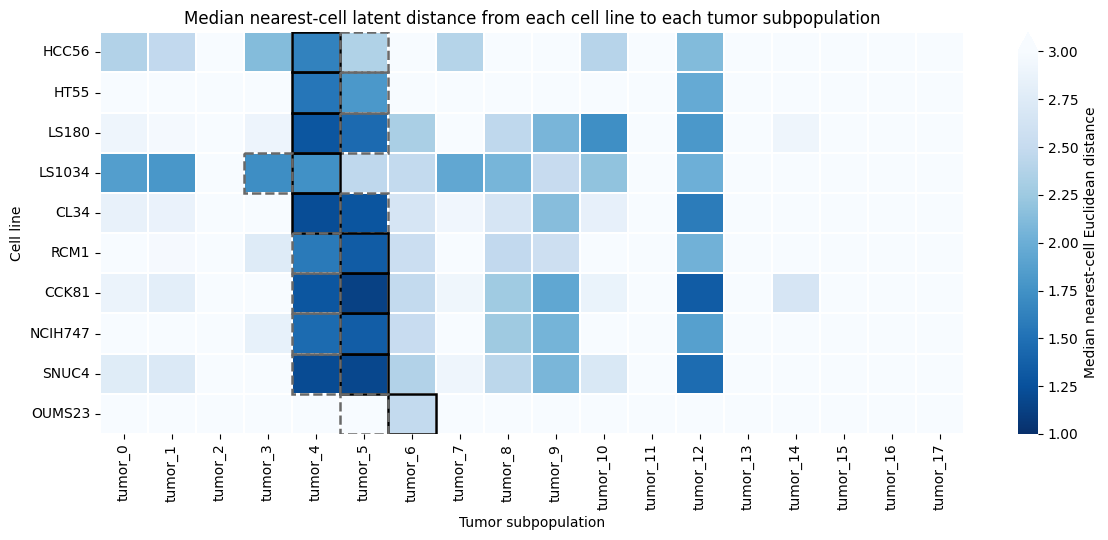

In [7]:
import seaborn as sns
from matplotlib.patches import Rectangle

fig_width = max(12, 0.65 * len(tumor_group_names))
fig_height = max(5, 0.55 * len(line_distance_matrix))
fig, ax = plt.subplots(
    figsize=(fig_width, fig_height),
)

sns.heatmap(
    line_distance_matrix,
    ax=ax,
    cmap="Blues_r",
    vmin=1.0,
    vmax=3.0,
    linewidths=0.3,
    cbar_kws={
        "label": "Median nearest-cell Euclidean distance",
        "extend": "max",
    },
)

for y, cell_line in enumerate(line_distance_matrix.index):
    for group, color, linestyle in [
        (str(line_matches.loc[cell_line, "primary_match"]), "black", "-"),
        (str(line_matches.loc[cell_line, "second_match"]), "dimgray", "--"),
    ]:
        if group in tumor_group_names:
            x = tumor_group_names.index(group)
            ax.add_patch(
                Rectangle(
                    (x, y), 1, 1, fill=False, edgecolor=color,
                    linewidth=1.8, linestyle=linestyle,
                )
            )

ax.set_xlabel("Tumor subpopulation")
ax.set_ylabel("Cell line")
ax.set_title(
    "Median nearest-cell latent distance from each cell line "
    "to each tumor subpopulation"
)
plt.tight_layout()
plt.show()

### Composition Enrichment
`q/p`: the unit composition over tumor subpopulations divided by the global tumor prevalence of each subpopulation. Values above 1 mean the unit's tumor neighbors are enriched for that subpopulation relative to the tumor.

descriptive sanity check only

In [8]:
tumor_prevalence = (
    combined_full.obs.loc[tumor_mask, "match_group"]
    .value_counts(normalize=True)
    .reindex(tumor_group_names)
)
line_enrichment = line_composition.div(tumor_prevalence.reindex(line_composition.columns), axis=1)
line_enrichment.round(2)

,tumor_0,tumor_1,tumor_2,tumor_3,tumor_4,tumor_5,tumor_6,tumor_7,tumor_8,tumor_9,tumor_10,tumor_11,tumor_12,tumor_13,tumor_14,tumor_15,tumor_16,tumor_17
cell_line,,,,,,,,,,,,,,,,,,
CCK81,0.22,0.25,0.0,0.04,2.31,4.71,0.02,0.04,0.01,0.22,0.00,0.00,2.45,0.00,0.02,0.00,0.0,0.0
CL34,0.03,0.06,0.0,0.15,4.02,3.78,0.02,0.01,0.04,0.26,0.11,0.00,1.49,0.02,0.00,0.00,0.0,0.0
HCC56,1.04,1.23,0.0,2.01,3.85,1.30,0.00,0.27,0.00,0.00,0.07,0.00,0.68,0.07,0.00,0.00,0.0,0.0
HT55,0.05,0.68,0.0,0.14,4.72,2.74,0.00,0.04,0.00,0.00,0.00,0.00,1.49,0.00,0.00,0.00,0.0,0.0
LS1034,1.32,0.89,0.0,2.97,2.44,0.38,0.08,0.49,0.53,0.75,0.47,0.02,1.49,0.33,0.00,0.00,0.0,0.0
LS180,0.32,0.19,0.0,0.39,3.76,2.45,0.17,0.08,0.15,0.58,1.87,0.05,0.56,0.20,0.00,0.00,0.0,0.0
NCIH747,0.06,0.22,0.0,0.92,3.05,4.25,0.24,0.19,0.12,0.64,0.00,0.00,0.80,0.00,0.00,0.05,0.0,0.0
OUMS23,0.00,0.04,0.0,1.31,0.33,1.66,34.27,0.33,0.19,2.15,0.00,0.00,1.34,0.05,0.00,0.56,0.0,0.0
RCM1,0.45,0.70,0.0,0.85,2.20,4.90,0.08,0.02,0.10,0.16,0.00,0.00,0.45,0.01,0.00,0.00,0.0,0.0


## Visual Latent Views
The frozen tumor-only and full Leiden labels on the combined UMAP, plus the cell line cells alone.

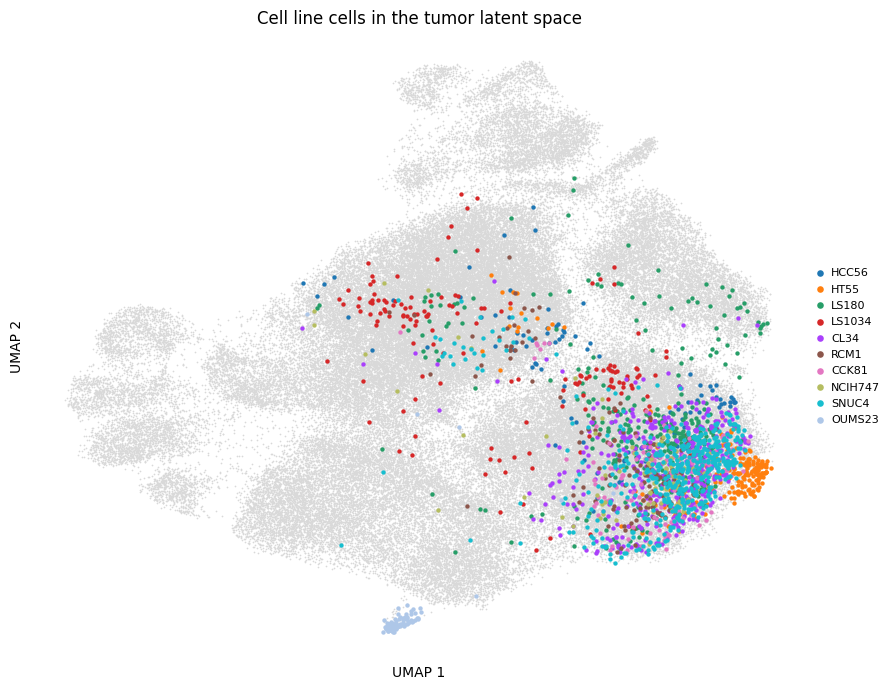

In [55]:
# UMAP with only the cell line cells colored.
from pathlib import Path
import matplotlib.pyplot as plt

FIG_DIR = Path.cwd().parents[1] / "figures" / "BIOVAL"
FIG_DIR.mkdir(parents=True, exist_ok=True)

umap = combined_full.obsm["X_umap"]
line_mask = combined_full.obs["dataset"].eq("cell_line").to_numpy()
tumor_mask = ~line_mask
line_labels = combined_full.obs.loc[line_mask, "cell_line"].astype(str)

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(
    umap[tumor_mask, 0], umap[tumor_mask, 1],
    s=1.5, c="#d9d9d9", linewidths=0, rasterized=True,
)
palette = ["#1f77b4", "#ff7f0e", "#279e68", "#d62728", "#aa40fc",
           "#8c564b", "#e377c2", "#b5bd61", "#17becf", "#aec7e8"]
line_order = [
    cell_line for cell_line in LINE_ORDER
    if cell_line in set(line_labels.unique())
]
for color, cell_line in zip(palette, line_order):
    mask = line_labels.eq(cell_line).to_numpy()
    ax.scatter(
        umap[line_mask][mask, 0], umap[line_mask][mask, 1],
        s=10, c=[color], linewidths=0, label=cell_line,
    )
ax.set_title("Cell line cells in the tumor latent space")
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
ax.legend(
    loc="center left", bbox_to_anchor=(1.0, 0.5),
    frameon=False, fontsize=8, markerscale=1.5,
)
plt.tight_layout()
fig.savefig(FIG_DIR / "bio_line_umap.png", dpi=300, bbox_inches="tight")
plt.show()

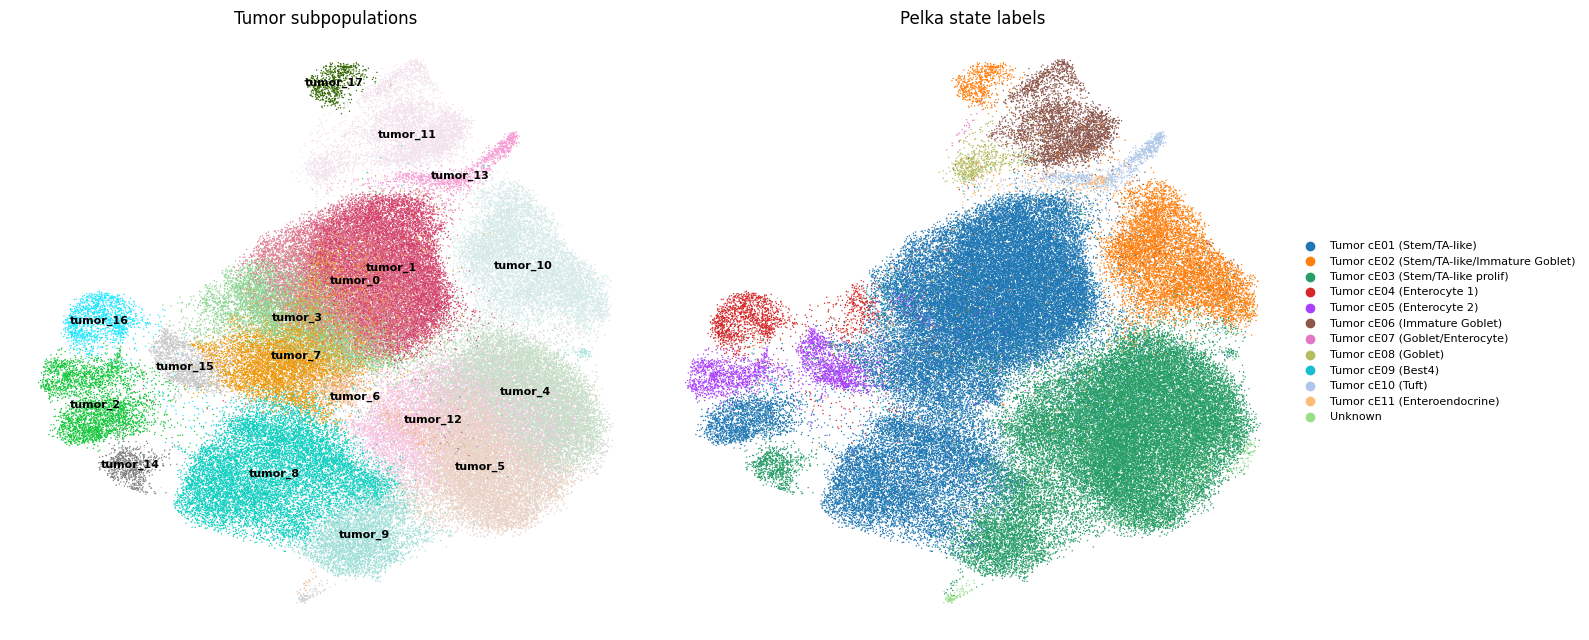

In [10]:
import matplotlib.pyplot as plt
import scanpy as sc
from pathlib import Path

FIG_DIR = Path.cwd().parents[1] / "figures" / "BIOVAL"
FIG_DIR.mkdir(parents=True, exist_ok=True)

tumor_mask = combined_full.obs["dataset"].eq("tumor")

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
sc.pl.umap(
    combined_full, color="label", ax=axes[1], show=False,
    legend_loc="right margin", legend_fontsize=8, frameon=False,
    size=4, na_color="#d9d9d9", title="Pelka state labels", na_in_legend=False
)
sc.pl.umap(
    combined_full, color="match_group", ax=axes[0], show=False,
    legend_loc="on data", legend_fontsize=8, frameon=False, mask_obs=combined_full.obs.dataset=="tumor",
    size=4, na_in_legend=False, title=f"Tumor subpopulations",
)
plt.tight_layout()
fig.savefig(FIG_DIR / "bio_subpop_umap.png", dpi=300, bbox_inches="tight")
plt.show()

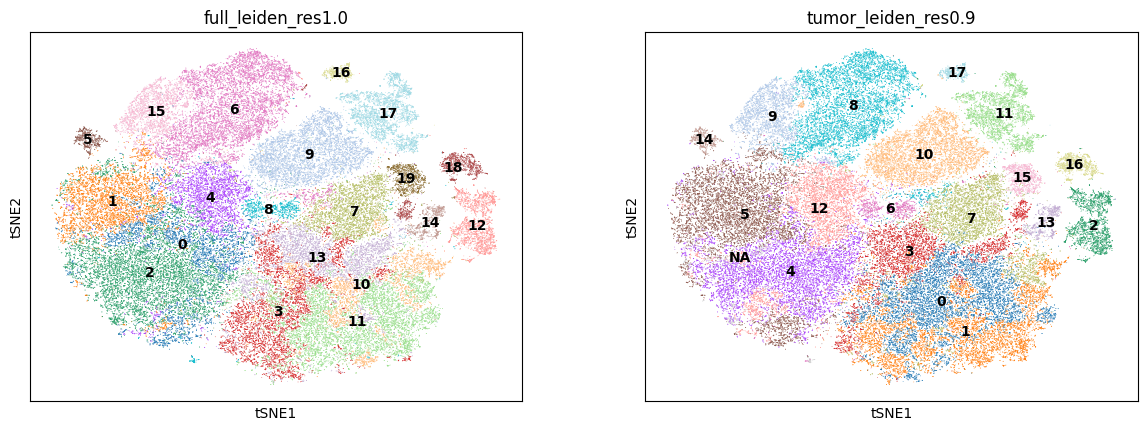

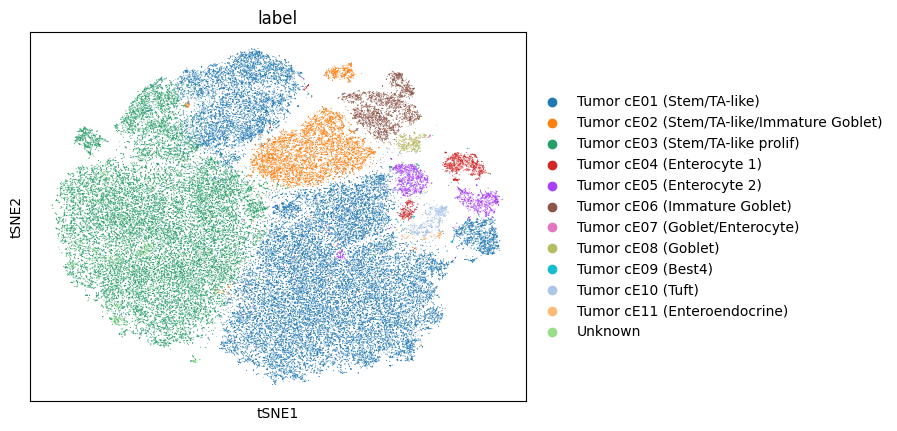

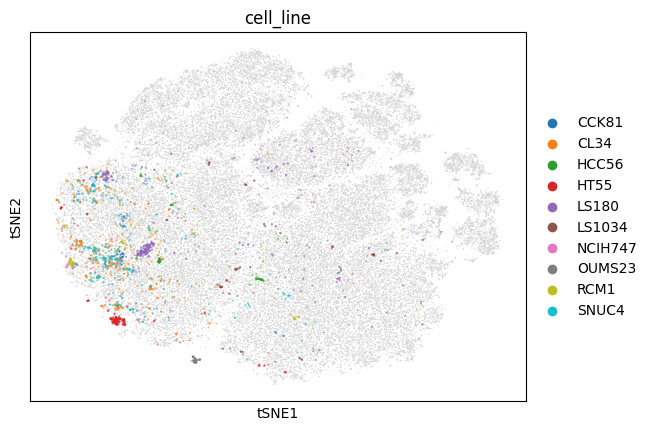

In [11]:
sc.pl.tsne(combined_full, color=[f_key, t_key], legend_loc="on data")
sc.pl.tsne(combined_full, color="label")

plot_view = combined_full[combined_full.obs["dataset"].eq("cell_line")].copy()
ax = sc.pl.tsne(combined_full, color=None, legend_loc=None, show=False)
sc.pl.tsne(plot_view, alpha=0.45, size=10, show=False, ax=ax, color="cell_line")
plt.show()

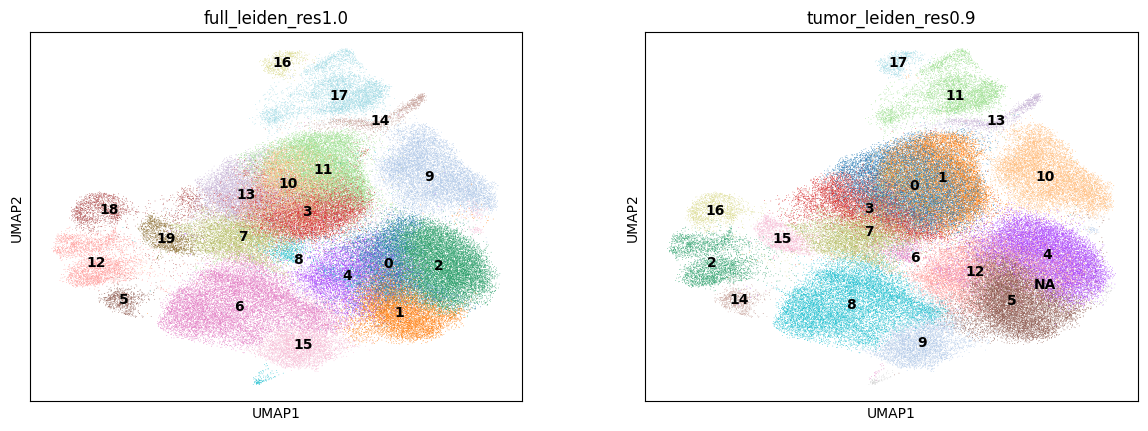

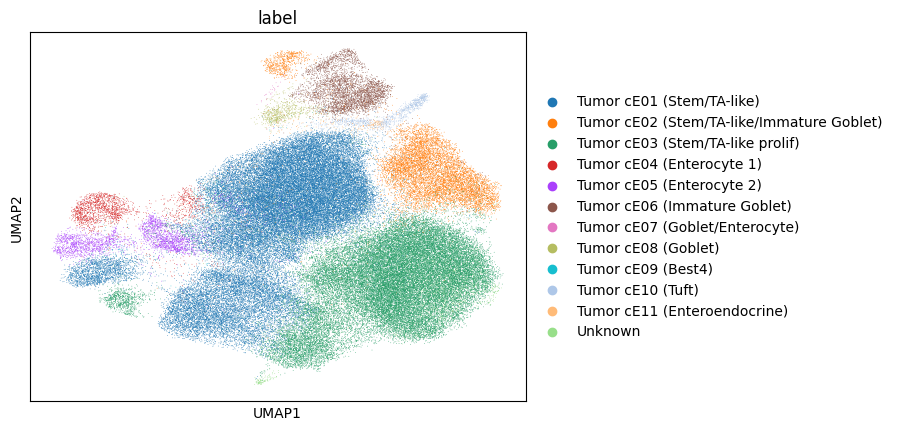

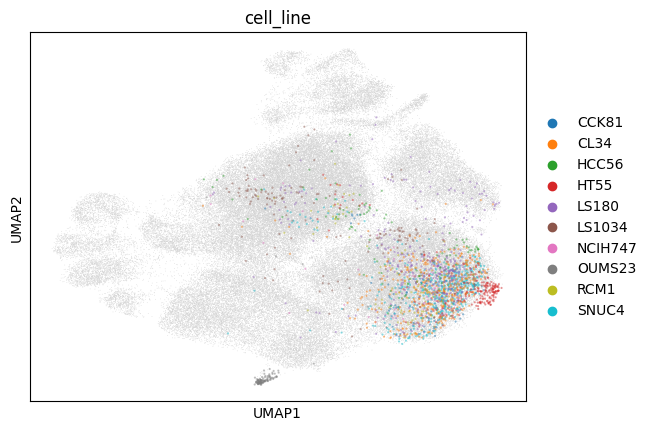

In [12]:
sc.pl.umap(combined_full, color=[f_key, t_key], legend_loc="on data")
sc.pl.umap(combined_full, color="label")

plot_view = combined_full[combined_full.obs["dataset"].eq("cell_line")].copy()
ax = sc.pl.umap(combined_full, color=None, legend_loc=None, show=False)
sc.pl.umap(plot_view, alpha=0.45, size=10, show=False, ax=ax, color="cell_line")
plt.show()

### Full-Leiden View of each cell line
Which cell lines occupy several full-Leiden states: possibly the basis for splitting a line into cell line subgroups in the fuller matching design. The current matching uses whole-line units only.

In [13]:
line_subgroups = pd.DataFrame({
    "line": combined_full.obs.loc[line_mask, "cell_line"].astype(str),
    "full_cluster": combined_full.obs.loc[line_mask, f_key].astype(str),
}).value_counts().rename("n_cells").reset_index()
line_subgroups["usable"] = line_subgroups["n_cells"] >= MIN_LINE_SUBGROUP_CELLS
line_subgroups#.style

,line,full_cluster,n_cells,usable
0,SNUC4,2,340,True
1,CL34,2,282,True
2,LS180,2,189,True
3,HT55,2,164,True
4,OUMS23,8,104,True
...,...,...,...,...
78,RCM1,10,1,False
79,RCM1,6,1,False
80,RCM1,4,1,False
81,SNUC4,13,1,False


In [14]:
def full_leiden_per_line(cell_line, adata=combined_full):
    plot_view = adata[adata.obs["cell_line"].eq(cell_line)].copy()

    print(f"############## {cell_line} ##############")
    print(plot_view.obs[f_key].value_counts())

    ax = sc.pl.umap(adata, color=None, legend_loc=None, show=False)
    sc.pl.umap(plot_view, color=f_key, size=20, alpha=0.45, show=False, ax=ax)
    plt.title(f"{cell_line} full Leiden ({f_key})")
    plt.show()


#for cell_line in sorted(combined_full.obs.loc[line_mask, "cell_line"].unique()):
#    full_leiden_per_line(cell_line)

## Matches Summary
The per-line match is written back to the cell line cells only; tumor cells keep `NA`. The table shows one row per line.

In [15]:
combined_full.obs["primary_match"] = pd.Series(pd.NA, index=combined_full.obs.index, dtype="string")
combined_full.obs["secondary_match"] = pd.Series(pd.NA, index=combined_full.obs.index, dtype="string")
combined_full.obs.loc[line_mask, "primary_match"] = (
    combined_full.obs.loc[line_mask, "cell_line"].map(line_matches["primary_match"]).astype("string")
)
combined_full.obs.loc[line_mask, "secondary_match"] = (
    combined_full.obs.loc[line_mask, "cell_line"].map(line_matches["second_match"]).astype("string")
)

combined_full.obs.loc[
    line_mask, ["cell_line", "match_group", "primary_match", "secondary_match"]
].drop_duplicates().style.hide()

cell_line,match_group,primary_match,secondary_match
NCIH747,line_NCIH747,tumor_5,tumor_4
LS1034,line_LS1034,tumor_4,tumor_3
RCM1,line_RCM1,tumor_5,tumor_4
CCK81,line_CCK81,tumor_5,tumor_4
SNUC4,line_SNUC4,tumor_5,tumor_4
CL34,line_CL34,tumor_4,tumor_5
LS180,line_LS180,tumor_4,tumor_5
OUMS23,line_OUMS23,tumor_6,tumor_5
HCC56,line_HCC56,tumor_4,tumor_5
HT55,line_HT55,tumor_4,tumor_5


### PLOTS: Candidate matching and confidence

The composition heatmap and margin panel show the primary match, runner-up, and ambiguity flags together.

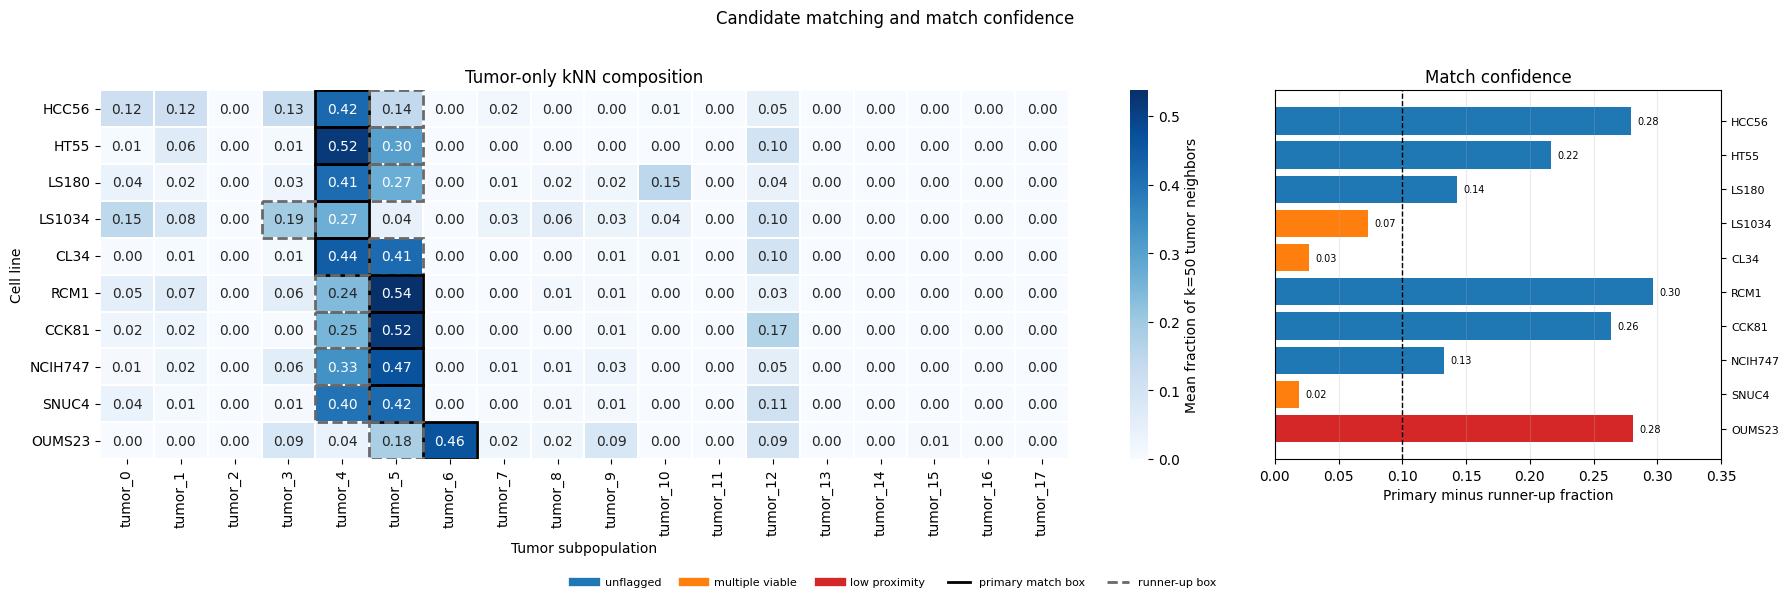

In [16]:
# Combined candidate-composition and match-confidence figure.
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import seaborn as sns

match_order = LINE_ORDER
composition_plot = line_composition.loc[match_order, tumor_group_names]

fig, (ax_heat, ax_margin) = plt.subplots(
    ncols=2,
    figsize=(18, max(5, 0.55 * len(match_order))),
    gridspec_kw={"width_ratios": [3.8, 1.4]},
)

sns.heatmap(
    composition_plot,
    ax=ax_heat,
    cmap="Blues",
    vmin=0,
    vmax=max(0.25, float(composition_plot.to_numpy().max())),
    annot=True,
    fmt=".2f",
    linewidths=0.3,
    cbar_kws={"label": "Mean fraction of k=50 tumor neighbors"},
)
ax_heat.set_xlabel("Tumor subpopulation")
ax_heat.set_ylabel("Cell line")
ax_heat.set_title("Tumor-only kNN composition")
ax_heat.set_xticklabels(ax_heat.get_xticklabels(), rotation=90)

for y, cell_line in enumerate(match_order):
    primary = line_matches.loc[cell_line, "primary_match"]
    second = line_matches.loc[cell_line, "second_match"]
    for group, color, linestyle in [
        (primary, "black", "-"),
        (second, "dimgray", "--"),
    ]:
        if group in tumor_group_names:
            x = tumor_group_names.index(group)
            ax_heat.add_patch(
                Rectangle(
                    (x, y), 1, 1, fill=False, edgecolor=color,
                    linewidth=2.0, linestyle=linestyle,
                )
            )

margin_values = line_matches.loc[match_order, "margin"]
colors = [
    "tab:red" if bool(line_matches.loc[name, "low_proximity"])
    else "tab:orange" if bool(line_matches.loc[name, "multiple_viable"])
    else "tab:blue"
    for name in match_order
]
ax_margin.barh(np.arange(len(match_order)), margin_values, color=colors)
ax_margin.invert_yaxis()
ax_margin.axvline(MARGIN_CANDIDATE, color="black", linestyle="--", linewidth=1)
ax_margin.set_yticks(np.arange(len(match_order)))
ax_margin.set_yticklabels(match_order, fontsize=8)
ax_margin.yaxis.tick_right()
ax_margin.set_xlim(0, max(margin_values) * 1.18)
for y, value in enumerate(margin_values):
    ax_margin.text(value + 0.005, y, f"{value:.2f}", va="center", fontsize=7)
ax_margin.set_xlabel("Primary minus runner-up fraction")
ax_margin.set_title("Match confidence")
ax_margin.grid(axis="x", alpha=0.25)
fig.legend(
    handles=[
        Line2D([0], [0], color="tab:blue", lw=6, label="unflagged"),
        Line2D([0], [0], color="tab:orange", lw=6, label="multiple viable"),
        Line2D([0], [0], color="tab:red", lw=6, label="low proximity"),
        Line2D([0], [0], color="black", lw=2, label="primary match box"),
        Line2D([0], [0], color="dimgray", lw=2, linestyle="--", label="runner-up box"),
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=5,
    frameon=False,
    fontsize=8,
)

fig.suptitle("Candidate matching and match confidence", y=1.02)
plt.tight_layout()
fig.savefig(
    FIG_DIR / "candidate_matching_confidence.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Tumor Subpopulation Signatures (DEG: HVG-only on scVI-tools)
This section defines tumor subpopulation signatures independently of the cell lines.

In [17]:
cfg = load_config()
DE_APPROACH = settings["approach"]
DE_CONFIG_ID = int(settings["config_id"])
DE_NUM_HVG = int(settings["num_hvg"])
DE_DIR = (ROOT / cfg["paths"]["models"] / "validation"
          / f"bio_{DE_APPROACH}_cfg{DE_CONFIG_ID:02d}" / "de_signatures")
DE_DIR.mkdir(parents=True, exist_ok=True)

run_dir = (ROOT / cfg["paths"]["hpo"]["runs"] / f"hvg{DE_NUM_HVG}"
           / f"config_{DE_CONFIG_ID:02d}" / DE_APPROACH)
combined_hvg = combined_full[:,combined_full.var.hvg == True].copy()
model_dir = run_dir / ("joint_scanvi" if DE_APPROACH == "joint" else "query")
model = scvi.model.SCANVI.load(str(model_dir), adata=combined_hvg)
assert combined_hvg.var_names.equals(model.adata.var_names)

print(f"run: {run_dir}")
print(f"model: {model_dir}")
print(f"combined_hvg: {combined_hvg.shape} (genes = model HVG set)")
print(f"model adata: {model.adata.shape}")

INFO     File /mnt/bigdisk/markus/CRC-scMFmap/models/hpo/runs/hvg3000/config_10/joint/joint_scanvi/model.pt already
         downloaded                                                                                                
run: /mnt/bigdisk/markus/CRC-scMFmap/models/hpo/runs/hvg3000/config_10/joint
model: /mnt/bigdisk/markus/CRC-scMFmap/models/hpo/runs/hvg3000/config_10/joint/joint_scanvi
combined_hvg: (110293, 3000) (genes = model HVG set)
model adata: (110293, 3000)


In [18]:
BATCH_CORRECTION_OPTIONS = [True, False]
PRIMARY_BATCH_CORRECTION = True
SIGNATURE_DELTA = 0.25
SIGNATURE_MODE = "change"

tumor_mask_de = combined_hvg.obs["dataset"].eq("tumor").to_numpy()
groups_de = combined_hvg.obs["match_group"].astype(str).to_numpy()
tumor_subpops = sorted(
    pd.unique(groups_de[tumor_mask_de]),
    key=tumor_group_sort_key,
)

def subpop_vs_rest_de(model, subpop, batch_correction):
    idx1 = tumor_mask_de & (groups_de == subpop)
    idx2 = tumor_mask_de & (groups_de != subpop)
    de = model.differential_expression(
        adata=combined_hvg,
        batch_correction=batch_correction,
        idx1=idx1,
        idx2=idx2,
        mode=SIGNATURE_MODE,
        delta=SIGNATURE_DELTA,
        silent=True,
    )
    de.index.name = "gene"
    de = de.reset_index()
    de.insert(0, "subpop", subpop)
    de.insert(1, "n_subpop", int(idx1.sum()))
    de.insert(2, "n_rest", int(idx2.sum()))
    return de

def make_lfc_ranking(de):
    return (
        de[["gene", "lfc_mean"]]
        .dropna(subset=["lfc_mean"])
        .drop_duplicates("gene")
        .sort_values(["lfc_mean", "gene"], ascending=[False, True])
        .reset_index(drop=True)
    )

def make_de_qc(de_by_subpop):
    return pd.DataFrame([
        {
            "signature": subpop,
            "n_subpop": int(de["n_subpop"].iloc[0]),
            "n_rest": int(de["n_rest"].iloc[0]),
            "n_genes": int(de["lfc_mean"].notna().sum()),
            "n_de_fdr_0.05": int(de["is_de_fdr_0.05"].sum()),
            "n_up_fdr_0.05": int((de["is_de_fdr_0.05"] & (de["lfc_mean"] > 0)).sum()),
            "n_down_fdr_0.05": int((de["is_de_fdr_0.05"] & (de["lfc_mean"] < 0)).sum()),
            "max_proba_de": float(de["proba_de"].max()),
            "median_abs_lfc": float(de["lfc_mean"].abs().median()),
            "top_up": ", ".join(de.nlargest(10, "lfc_mean")["gene"]),
            "top_down": ", ".join(de.nsmallest(10, "lfc_mean")["gene"]),
        }
        for subpop, de in de_by_subpop.items()
    ])


de_by_batch_correction = {}
rankings_by_batch_correction = {}
de_qc_by_batch_correction = {}

for batch_correction in BATCH_CORRECTION_OPTIONS:
    variant = f"batch_correction_{str(batch_correction).lower()}"
    variant_dir = DE_DIR / variant
    variant_dir.mkdir(parents=True, exist_ok=True)

    de_by_subpop = {}
    rankings = {}

    for subpop in tumor_subpops:
        de_path = variant_dir / f"scvi_de_tumor_{subpop}_vs_rest.csv"
        ranking_path = variant_dir / f"ranking_tumor_{subpop}_vs_rest.csv"

        if de_path.exists():
            de = pd.read_csv(de_path)
            print(f"loaded {variant}: {subpop}")
        else:
            print(f"running {variant}: {subpop}")
            de = subpop_vs_rest_de(model, subpop, batch_correction)
            de.to_csv(de_path, index=False)

        if ranking_path.exists():
            ranking = pd.read_csv(ranking_path)
        else:
            ranking = make_lfc_ranking(de)
            ranking.to_csv(ranking_path, index=False)

        de_by_subpop[subpop] = de
        rankings[subpop] = ranking
        print(f"  {subpop}: {de['n_subpop'].iloc[0]} vs {de['n_rest'].iloc[0]} cells")

    de_qc = make_de_qc(de_by_subpop)
    de_qc.to_csv(variant_dir / "de_qc.csv", index=False)
    with open(variant_dir / "manifest.json", "w") as handle:
        json.dump({
            "batch_correction": batch_correction,
            "signature_mode": SIGNATURE_MODE,
            "signature_delta": SIGNATURE_DELTA,
            "n_subpopulations": len(tumor_subpops),
            "subpopulations": tumor_subpops,
        }, handle, indent=2)

    de_by_batch_correction[batch_correction] = de_by_subpop
    rankings_by_batch_correction[batch_correction] = rankings
    de_qc_by_batch_correction[batch_correction] = de_qc

# Keep the existing downstream GSEA cells on the primary branch.
BATCH_CORRECTION = PRIMARY_BATCH_CORRECTION
de_by_subpop = de_by_batch_correction[PRIMARY_BATCH_CORRECTION]
rankings = rankings_by_batch_correction[PRIMARY_BATCH_CORRECTION]
de_qc = de_qc_by_batch_correction[PRIMARY_BATCH_CORRECTION]

print("DE cache complete:")
for batch_correction in BATCH_CORRECTION_OPTIONS:
    print(f"  batch_correction={batch_correction}: {len(de_by_batch_correction[batch_correction])} subpopulations")

loaded batch_correction_true: tumor_0
  tumor_0: 12126 vs 96005 cells
loaded batch_correction_true: tumor_1
  tumor_1: 10323 vs 97808 cells
loaded batch_correction_true: tumor_2
  tumor_2: 3276 vs 104855 cells
loaded batch_correction_true: tumor_3
  tumor_3: 7047 vs 101084 cells
loaded batch_correction_true: tumor_4
  tumor_4: 11847 vs 96284 cells
loaded batch_correction_true: tumor_5
  tumor_5: 11858 vs 96273 cells
loaded batch_correction_true: tumor_6
  tumor_6: 1461 vs 106670 cells
loaded batch_correction_true: tumor_7
  tumor_7: 7357 vs 100774 cells
loaded batch_correction_true: tumor_8
  tumor_8: 11922 vs 96209 cells
loaded batch_correction_true: tumor_9
  tumor_9: 4291 vs 103840 cells
loaded batch_correction_true: tumor_10
  tumor_10: 8621 vs 99510 cells
loaded batch_correction_true: tumor_11
  tumor_11: 4903 vs 103228 cells
loaded batch_correction_true: tumor_12
  tumor_12: 7351 vs 100780 cells
loaded batch_correction_true: tumor_13
  tumor_13: 1200 vs 106931 cells
loaded batch_

In [19]:
def subpop_lfc_ranking(subpop):
    de = de_by_subpop[subpop].dropna(subset=["lfc_mean"])
    return de.set_index("gene")["lfc_mean"].sort_values(ascending=False)

#for subpop in tumor_subpops:
#    print("\n",subpop , subpop_lfc_ranking(subpop).head(10))

In [20]:
de_qc[de_qc["signature"] == "tumor_4"]

,signature,n_subpop,n_rest,n_genes,n_de_fdr_0.05,n_up_fdr_0.05,n_down_fdr_0.05,max_proba_de,median_abs_lfc,top_up,top_down
4,tumor_4,11847,96284,3000,0,0,0,0.875,0.290399,"RRM2, MYBL2, CDK1, UBE2C, PKMYT1, NPPB, HIST1H...","CLCA1, BEST4, ITLN1, APOA4, S100A8, MNDA, CA7,..."


### Hallmark - Pathways of Tumor Subpops
Preranked GSEA (`gseapy.prerank`) on the full signed `lfc_mean` ranking of each tumor-only subpopulation versus the remaining tumor cells, using the cleaned Hallmark GMT (`data/Gene_sets/h_cleaned.all.v2023.1.Hs.symbols.gmt`).

Notes:
- 1,000 gene-set permutations with `min_size=15` and `max_size=500` -> just the `gseapy` defaults 
- NES sign, leading edge, and the runner-up/direct contrast, not the q-value alone.

In [21]:
import gseapy as gp

HALLMARK_GMT = ROOT / "data" / "Gene_sets" / "h_cleaned.all.v2023.1.Hs.symbols.gmt"
GSEA_DIR = DE_DIR / "gsea_hallmark"
GSEA_DIR.mkdir(parents=True, exist_ok=True)

def read_gmt(path):
    gene_sets = {}
    with open(path) as handle:
        for line in handle:
            fields = line.rstrip("\n").split("\t")
            if len(fields) < 3:
                continue
            term = fields[0].replace("HALLMARK_", "")
            gene_sets[term] = [gene for gene in fields[2:] if gene]
    return gene_sets
hallmark_sets = read_gmt(HALLMARK_GMT)

def run_hallmark_prerank(ranking, comparison):
    res = gp.prerank(
        rnk=ranking, gene_sets=str(HALLMARK_GMT), seed=SEED,#below this is just defaults
        method="permutation",
        permutation_num=1000,
        min_size=15,
        max_size=500,
        weight=1,
        ascending=False,
        outdir=None,
    ).res2d.copy()

    res = res.rename(columns={
        "Term": "pathway",
        "ES": "es",
        "NES": "nes",
        "NOM p-val": "nom_pval",
        "FDR q-val": "fdr_qval",
        "FWER p-val": "fwer_pval",
        "Tag %": "tag_pct",
        "Gene %": "gene_pct",
        "Lead_genes": "lead_genes",
    })
    res["pathway"] = res["pathway"].str.replace("^HALLMARK_", "", regex=True)
    res["set_size"] = res["pathway"].map(lambda term: len(hallmark_sets.get(term, [])))
    res["overlap"] = res["pathway"].map(
        lambda term: len(set(ranking["gene"]).intersection(hallmark_sets.get(term, [])))
    )
    keep = [
        "pathway",
        "es",
        "nes",
        "nom_pval",
        "fdr_qval",
        "fwer_pval",
        "tag_pct",
        "gene_pct",
        "overlap",
        "set_size",
        "lead_genes",
    ]
    res = res[keep]
    res.insert(0, "comparison", comparison)
    return res


results_gsea_tumor = []
for subpop in rankings:
    res = run_hallmark_prerank(rankings[subpop], f"{subpop}-vs-RestTumor")
    res.insert(0, "subpopulation", subpop)
    results_gsea_tumor.append(res)
results_gsea_tumor = pd.concat(results_gsea_tumor, ignore_index=True)
results_gsea_tumor.to_csv(GSEA_DIR / "hallmark_prerank_tumor.csv", index=False)

print(f"Gene sets: {len(hallmark_sets)}; results: {results_gsea_tumor.shape}")
print(f"Saved: {GSEA_DIR / 'hallmark_prerank_tumor.csv'}")
results_gsea_tumor.head(3)

2026-09-26 03:18:40,056 [WARNING] Duplicated values found in preranked stats: 0.03% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-09-26 03:18:45,066 [WARNING] Duplicated values found in preranked stats: 0.03% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-09-26 03:18:45,841 [WARNING] Duplicated values found in preranked stats: 0.03% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


Gene sets: 50; results: (810, 13)
Saved: /mnt/bigdisk/markus/CRC-scMFmap/models/validation/bio_joint_cfg10/de_signatures/gsea_hallmark/hallmark_prerank_tumor.csv


,subpopulation,comparison,pathway,es,nes,nom_pval,fdr_qval,fwer_pval,tag_pct,gene_pct,overlap,set_size,lead_genes
0,tumor_0,tumor_0-vs-RestTumor,G2M_CHECKPOINT,-0.903830,-2.802479,0.0,0.0,0.0,38/49,4.73%,49,200,UBE2C;CDK1;TOP2A;BIRC5;CCNA2;PBK;NUSAP1;CDC20;...
1,tumor_0,tumor_0-vs-RestTumor,E2F_TARGETS,-0.893533,-2.769916,0.0,0.0,0.0,39/51,4.73%,51,200,RRM2;CDK1;TOP2A;BIRC5;CDC20;AURKB;MYBL2;PTTG1;...
2,tumor_0,tumor_0-vs-RestTumor,MITOTIC_SPINDLE,-0.853507,-2.586639,0.0,0.0,0.0,22/44,4.73%,44,199,CDK1;TOP2A;BIRC5;NUSAP1;NEK2;DLGAP5;TPX2;PLK1;...


In [22]:
def show_gsea_tumor(subpop):
    return results_gsea_tumor[results_gsea_tumor["subpopulation"] == subpop]

def hallmark_direction_summary(fdr=0.05):
    rows = []
    for subpop in tumor_subpops:
        res = show_gsea_tumor(subpop)
        sig = res[res["fdr_qval"] <= fdr]

        ncells_subpop_by_sig = de_qc.set_index("signature")["n_subpop"].to_dict()
        rows.append({
            "subpopulation": subpop,
            "ncells_subpop": int(ncells_subpop_by_sig[subpop]),
            "n_sig_fdr": len(sig),
            "n_enriched": int((sig["nes"] > 0).sum()),
            "n_depleted": int((sig["nes"] < 0).sum()),
            "top_enriched": ", ".join(sig.nlargest(3, "nes")["pathway"]),
            "top_depleted": ", ".join(sig.nsmallest(3, "nes")["pathway"]),
        })
    return pd.DataFrame(rows)

def show_hallmark_sides(subpop, fdr=0.05):
    res = show_gsea_tumor(subpop)
    sig = res[res["fdr_qval"] <= fdr].copy()
    sig["direction"] = np.where(sig["nes"] > 0, "enriched", "depleted")
    cols = ["direction", "pathway", "nes", "nom_pval", "fdr_qval", "overlap", "set_size", "lead_genes"]
    return sig.sort_values("nes", ascending=False)[cols].reset_index(drop=True)

hallmark_direction_summary()

,subpopulation,ncells_subpop,n_sig_fdr,n_enriched,n_depleted,top_enriched,top_depleted
0,tumor_0,12126,10,1,9,"CHOLESTEROL_HOMEOSTASIS, IL6_JAK_STAT3_SIGNALI...","G2M_CHECKPOINT, E2F_TARGETS, MITOTIC_SPINDLE"
1,tumor_1,10323,8,0,8,"ESTROGEN_RESPONSE_LATE, GLYCOLYSIS, SPERMATOGE...","E2F_TARGETS, G2M_CHECKPOINT, MITOTIC_SPINDLE"
2,tumor_2,3276,6,0,6,"DNA_REPAIR, MTORC1_SIGNALING, MITOTIC_SPINDLE","E2F_TARGETS, G2M_CHECKPOINT, MYC_TARGETS_V1"
3,tumor_3,7047,24,15,9,"TNFA_SIGNALING_VIA_NFKB, HYPOXIA, APICAL_JUNCTION","G2M_CHECKPOINT, E2F_TARGETS, MITOTIC_SPINDLE"
4,tumor_4,11847,20,13,7,"E2F_TARGETS, G2M_CHECKPOINT, MITOTIC_SPINDLE","INFLAMMATORY_RESPONSE, COAGULATION, PANCREAS_B..."
5,tumor_5,11858,18,12,6,"E2F_TARGETS, G2M_CHECKPOINT, MITOTIC_SPINDLE","KRAS_SIGNALING_DN, INFLAMMATORY_RESPONSE, KRAS..."
6,tumor_6,1461,8,5,3,"ALLOGRAFT_REJECTION, INFLAMMATORY_RESPONSE, CO...","MYC_TARGETS_V1, DNA_REPAIR, OXIDATIVE_PHOSPHOR..."
7,tumor_7,7357,17,0,17,"UNFOLDED_PROTEIN_RESPONSE, UV_RESPONSE_UP, EST...","G2M_CHECKPOINT, E2F_TARGETS, MYC_TARGETS_V1"
8,tumor_8,11922,4,4,0,"REACTIVE_OXYGEN_SPECIES_PATHWAY, MYC_TARGETS_V...","OXIDATIVE_PHOSPHORYLATION, DNA_REPAIR, MYC_TAR..."
9,tumor_9,4291,13,11,2,"G2M_CHECKPOINT, E2F_TARGETS, MYC_TARGETS_V1","TNFA_SIGNALING_VIA_NFKB, INFLAMMATORY_RESPONSE..."


#### Detailed GSEA results for each subpop vs rest

In [23]:
show_gsea_tumor("tumor_4").head()

,subpopulation,comparison,pathway,es,nes,nom_pval,fdr_qval,fwer_pval,tag_pct,gene_pct,overlap,set_size,lead_genes
180,tumor_4,tumor_4-vs-RestTumor,E2F_TARGETS,0.943473,3.339913,0.0,0.000000,0.000,47/51,4.93%,51,200,RRM2;MYBL2;CDK1;TOP2A;ATAD2;ASF1B;TK1;MKI67;BR...
181,tumor_4,tumor_4-vs-RestTumor,G2M_CHECKPOINT,0.924136,3.291843,0.0,0.000000,0.000,44/49,7.00%,49,200,MYBL2;CDK1;UBE2C;TOP2A;CCNA2;PBK;CDC6;MKI67;NU...
182,tumor_4,tumor_4-vs-RestTumor,MITOTIC_SPINDLE,0.790888,2.726009,0.0,0.000000,0.000,24/44,6.87%,44,199,CDK1;TOP2A;NUSAP1;BIRC5;ANLN;BRCA2;TPX2;KIF11;...
183,tumor_4,tumor_4-vs-RestTumor,MYC_TARGETS_V1,0.793893,2.379644,0.0,0.000000,0.000,16/25,10.93%,25,200,CCNA2;TYMS;MCM6;MAD2L1;MCM4;PCNA;CDC20;KPNA2;S...
184,tumor_4,tumor_4-vs-RestTumor,MTORC1_SIGNALING,0.570383,2.044040,0.0,0.000379,0.002,24/57,14.47%,57,200,RRM2;DHFR;MCM4;PLK1;FADS1;BUB1;AURKA;DDX39A;FA...


#### pairwise GSEA for tumor subpops

In [24]:
# Direct tumor_4-vs-tumor_5 contrast: the shared-vs-rest comparisons dilute exactly
# this difference, so test the pair head to head (positive lfc_mean = up in tumor_4).
PAIRWISE = ("tumor_4", "tumor_5")

def pairwise_de(model, group1, group2):
    groups = model.adata.obs["match_group"].to_numpy()
    idx1 = tumor_mask.to_numpy() & (groups == group1)
    idx2 = tumor_mask.to_numpy() & (groups == group2)
    de = model.differential_expression(
        adata=combined_hvg,
        batch_correction=BATCH_CORRECTION,
        idx1=idx1,
        idx2=idx2,
        mode=SIGNATURE_MODE,
        delta=SIGNATURE_DELTA,
        silent=True,
    )
    de.index.name = "gene"
    de = de.reset_index()
    de.insert(0, "n_group1", int(idx1.sum()))
    de.insert(1, "n_group2", int(idx2.sum()))
    return de

group1, group2 = PAIRWISE
pairwise_comparison = f"{group1}-vs-{group2}"
de_pairwise = pairwise_de(model, group1, group2)
de_pairwise.to_csv(DE_DIR / f"scvi_de_{group1}_vs_{group2}.csv", index=False)

pairwise_ranking = (
    de_pairwise[["gene", "lfc_mean"]]
    .dropna(subset=["lfc_mean"])
    .drop_duplicates("gene")
    .sort_values(["lfc_mean", "gene"], ascending=[False, True])
    .reset_index(drop=True)
)
results_gsea_pairwise = run_hallmark_prerank(pairwise_ranking, pairwise_comparison)
results_gsea_pairwise.to_csv(GSEA_DIR / f"hallmark_prerank_{group1}_vs_{group2}.csv", index=False)

print(f"{pairwise_comparison}: {de_pairwise['n_group1'].iloc[0]} vs "
      f"{de_pairwise['n_group2'].iloc[0]} cells")
#results_gsea_pairwise.sort_values("nes", ascending=False).head(15)

tumor_4-vs-tumor_5: 11847 vs 11858 cells


In [25]:
def show_hallmark_pairwise(res, fdr=0.05):
    sig = res[res["fdr_qval"] <= fdr].copy()
    sig["direction"] = np.where(sig["nes"] > 0, f"up in {group1}", f"up in {group2}")
    cols = ["direction", "pathway", "nes", "nom_pval", "fdr_qval", "overlap", "set_size", "lead_genes"]
    return sig.sort_values("nes", ascending=False)[cols].reset_index(drop=True)

show_hallmark_pairwise(results_gsea_pairwise)

,direction,pathway,nes,nom_pval,fdr_qval,overlap,set_size,lead_genes
0,up in tumor_4,ESTROGEN_RESPONSE_EARLY,1.982308,0.000000,0.000000,63,200,REEP1;TIAM1;HSPB8;KCNK15;TFF3;CLIC3;KLK10;MUC1...
1,up in tumor_4,TNFA_SIGNALING_VIA_NFKB,1.806165,0.000000,0.009832,113,200,ATF3;HBEGF;NR4A1;EGR1;FOSB;CDKN1A;TNFSF9;DUSP5...
2,up in tumor_4,UV_RESPONSE_UP,1.797567,0.000000,0.007125,52,158,CCNE1;ATF3;NR4A1;ENO2;FEN1;FOSB;RASGRP1;COL2A1...
3,up in tumor_4,P53_PATHWAY,1.758161,0.002525,0.008977,63,200,ATF3;HBEGF;CDKN1A;NDRG1;TNFSF9;PCNA;MXD1;LIF;R...
4,up in tumor_4,HYPOXIA,1.616333,0.006002,0.048220,87,200,RRAGD;ATF3;ENO2;CDKN1A;NDRG1;ERRFI1;CP;EGFR;ZF...
5,up in tumor_4,APICAL_SURFACE,1.606568,0.018207,0.044886,17,44,BRCA1;CX3CL1;ATP6V0A4;CD160;PLAUR;DCBLD2;LYPD3...
6,up in tumor_5,REACTIVE_OXYGEN_SPECIES_PATHWAY,-1.630073,0.024561,0.019002,19,49,PRDX1;SOD1;HHEX;NQO1;TXNRD2;TXN;PRDX2;GCLM;GPX3
7,up in tumor_5,INTERFERON_GAMMA_RESPONSE,-1.663790,0.006494,0.016270,85,200,PSMA3;IDO1;PSMB2;PSME2;CXCL10;CXCL9;CASP1;PSMB...
8,up in tumor_5,INTERFERON_ALPHA_RESPONSE,-1.697430,0.000000,0.015783,44,97,PSMA3;PSME2;CXCL10;CASP1;PSMB8;PSME1;PSMB9;IFI...
9,up in tumor_5,SPERMATOGENESIS,-1.830879,0.007547,0.008576,24,135,CCNB2;CDKN3;BUB1;NEK2;LDHC;AURKA


## PLOT: Selected tumor-subpopulation GSEA

The heatmap shows the strongest Hallmark NES values for the selected tumor subpopulations.

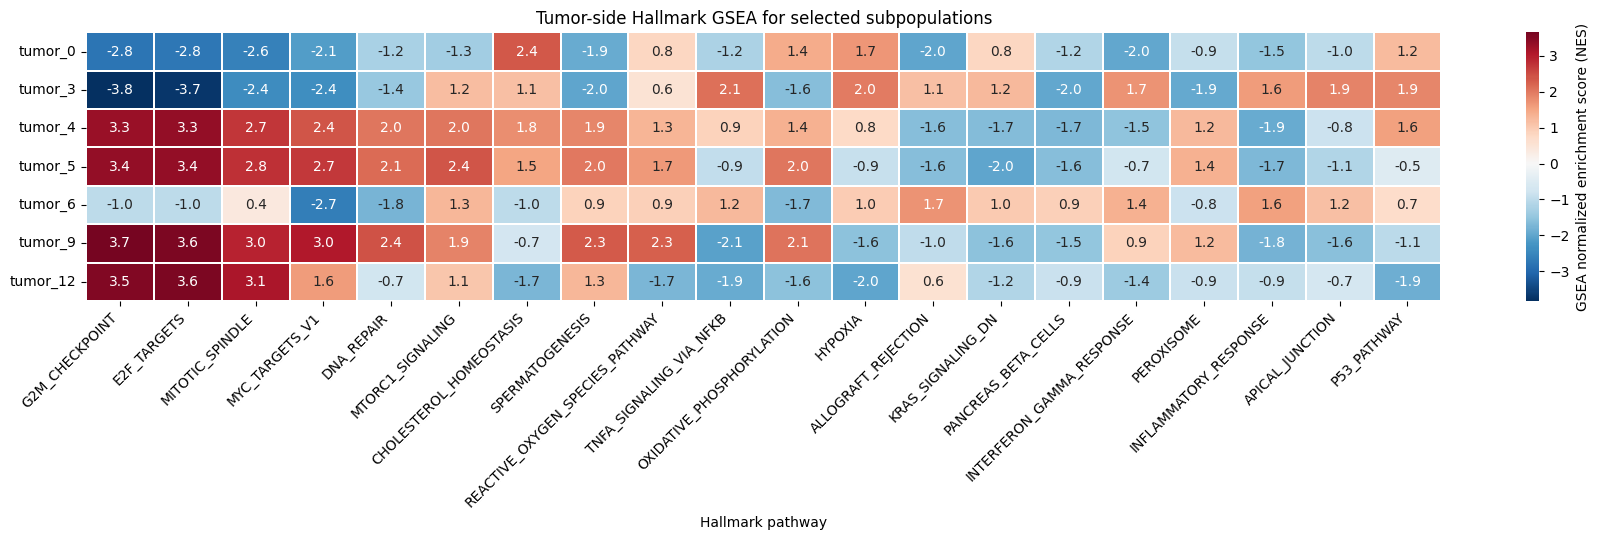

In [54]:
import seaborn as sns

# Tumor GSEA heatmap for the selected subpopulations.
selected_tumor_subpop_set = {"tumor_0", "tumor_3", "tumor_4", "tumor_5", "tumor_6", "tumor_9", "tumor_12"}
selected_tumor_subpops = [group for group in TUMOR_ORDER if group in selected_tumor_subpop_set]
gsea_focus = results_gsea_tumor.loc[
    results_gsea_tumor["subpopulation"].isin(selected_tumor_subpops)
].copy()

pathway_strength = (
    gsea_focus.groupby("pathway")["nes"]
    .apply(lambda values: values.abs().max())
    .sort_values(ascending=False)
)
gsea_pathways = pathway_strength.head(20).index.tolist()
gsea_heatmap = (
    gsea_focus[gsea_focus["pathway"].isin(gsea_pathways)]
    .pivot(index="subpopulation", columns="pathway", values="nes")
    .reindex(index=selected_tumor_subpops, columns=gsea_pathways)
)

fig, ax = plt.subplots(figsize=(18, 5.5))
sns.heatmap(
    gsea_heatmap,
    ax=ax,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".1f",
    linewidths=0.3,
    cbar_kws={"label": "GSEA normalized enrichment score (NES)"},
)
ax.set_title("Tumor-side Hallmark GSEA for selected subpopulations")
ax.set_xlabel("Hallmark pathway")
ax.set_ylabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.tick_params(axis="y", labelrotation=0)
plt.tight_layout()
fig.savefig(
    FIG_DIR / "tumor_gsea_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# DEG/GSEA on Cell Lines
all CL vs all subpops

In [27]:
# Direct cell line vs tumor subpopulation DE, batch corrected.
# lfc_mean > 0 means up in the cell line relative to the tumor subpopulation.
LINE_VS_TUMOR_DIR = DE_DIR / "line_vs_tumor"
LINE_VS_TUMOR_DIR.mkdir(parents=True, exist_ok=True)
LINE_VS_TUMOR_BATCH_CORRECTION = True

line_mask_de = combined_hvg.obs["dataset"].eq("cell_line").to_numpy()
line_groups = sorted(pd.unique(groups_de[line_mask_de]))
tumor_subpops_lvt = sorted(pd.unique(groups_de[tumor_mask_de]), key=tumor_group_sort_key)

def line_vs_tumor_de(cell_line_group, subpop, batch_correction=LINE_VS_TUMOR_BATCH_CORRECTION):
    idx1 = line_mask_de & (groups_de == cell_line_group)
    idx2 = tumor_mask_de & (groups_de == subpop)
    de = model.differential_expression(
        adata=combined_hvg,
        batch_correction=batch_correction,
        idx1=idx1,
        idx2=idx2,
        mode=SIGNATURE_MODE,
        delta=SIGNATURE_DELTA,
        silent=True,
    )
    de.index.name = "gene"
    de = de.reset_index()
    de.insert(0, "cell_line", cell_line_group.replace("line_", ""))
    de.insert(1, "subpop", subpop)
    de.insert(2, "n_line", int(idx1.sum()))
    de.insert(3, "n_subpop", int(idx2.sum()))
    return de

line_vs_tumor_de_by_pair = {}
line_vs_tumor_rankings = {}

for cell_line_group in line_groups:
    for subpop in tumor_subpops_lvt:
        pair = f"{cell_line_group}_vs_{subpop}"
        de_path = LINE_VS_TUMOR_DIR / f"scvi_de_{pair}.csv"
        ranking_path = LINE_VS_TUMOR_DIR / f"ranking_{pair}.csv"

        if de_path.exists():
            de = pd.read_csv(de_path)
            print(f"loaded {pair}")
        else:
            print(f"running {pair}")
            de = line_vs_tumor_de(cell_line_group, subpop)
            de.to_csv(de_path, index=False)

        if ranking_path.exists():
            ranking = pd.read_csv(ranking_path)
        else:
            ranking = make_lfc_ranking(de)
            ranking.to_csv(ranking_path, index=False)

        line_vs_tumor_de_by_pair[(cell_line_group, subpop)] = de
        line_vs_tumor_rankings[(cell_line_group, subpop)] = ranking

line_vs_tumor_qc = pd.DataFrame([
    {
        "cell_line": cell_line_group.replace("line_", ""),
        "subpop": subpop,
        "n_line": int(de["n_line"].iloc[0]),
        "n_subpop": int(de["n_subpop"].iloc[0]),
        "n_genes": int(de["lfc_mean"].notna().sum()),
        "n_de_fdr_0.05": int(de["is_de_fdr_0.05"].sum()),
        "n_up_fdr_0.05": int((de["is_de_fdr_0.05"] & (de["lfc_mean"] > 0)).sum()),
        "n_down_fdr_0.05": int((de["is_de_fdr_0.05"] & (de["lfc_mean"] < 0)).sum()),
        "max_proba_de": float(de["proba_de"].max()),
        "median_abs_lfc": float(de["lfc_mean"].abs().median()),
        "top_up_in_line": ", ".join(de.nlargest(10, "lfc_mean")["gene"]),
        "top_down_in_line": ", ".join(de.nsmallest(10, "lfc_mean")["gene"]),
    }
    for (cell_line_group, subpop), de in line_vs_tumor_de_by_pair.items()
]).sort_values(["cell_line", "subpop"]).reset_index(drop=True)
line_vs_tumor_qc.to_csv(LINE_VS_TUMOR_DIR / "line_vs_tumor_de_qc.csv", index=False)

with open(LINE_VS_TUMOR_DIR / "manifest.json", "w") as handle:
    json.dump({
        "model": "config_10_joint_scanvi",
        "batch_correction": LINE_VS_TUMOR_BATCH_CORRECTION,
        "signature_mode": SIGNATURE_MODE,
        "signature_delta": SIGNATURE_DELTA,
        "direction": "lfc_mean > 0 means up in the cell line relative to the tumor subpopulation",
        "n_comparisons": len(line_vs_tumor_de_by_pair),
        "cell_lines": [g.replace("line_", "") for g in line_groups],
        "tumor_subpopulations": tumor_subpops_lvt,
    }, handle, indent=2)

print(f"DE cache complete: {len(line_vs_tumor_de_by_pair)} comparisons "
      f"({len(line_groups)} lines x {len(tumor_subpops_lvt)} subpopulations)")
line_vs_tumor_qc.head()

loaded line_CCK81_vs_tumor_0
loaded line_CCK81_vs_tumor_1
loaded line_CCK81_vs_tumor_2
loaded line_CCK81_vs_tumor_3
loaded line_CCK81_vs_tumor_4
loaded line_CCK81_vs_tumor_5
loaded line_CCK81_vs_tumor_6
loaded line_CCK81_vs_tumor_7
loaded line_CCK81_vs_tumor_8
loaded line_CCK81_vs_tumor_9
loaded line_CCK81_vs_tumor_10
loaded line_CCK81_vs_tumor_11
loaded line_CCK81_vs_tumor_12
loaded line_CCK81_vs_tumor_13
loaded line_CCK81_vs_tumor_14
loaded line_CCK81_vs_tumor_15
loaded line_CCK81_vs_tumor_16
loaded line_CCK81_vs_tumor_17
loaded line_CL34_vs_tumor_0
loaded line_CL34_vs_tumor_1
loaded line_CL34_vs_tumor_2
loaded line_CL34_vs_tumor_3
loaded line_CL34_vs_tumor_4
loaded line_CL34_vs_tumor_5
loaded line_CL34_vs_tumor_6
loaded line_CL34_vs_tumor_7
loaded line_CL34_vs_tumor_8
loaded line_CL34_vs_tumor_9
loaded line_CL34_vs_tumor_10
loaded line_CL34_vs_tumor_11
loaded line_CL34_vs_tumor_12
loaded line_CL34_vs_tumor_13
loaded line_CL34_vs_tumor_14
loaded line_CL34_vs_tumor_15
loaded line_CL34

,cell_line,subpop,n_line,n_subpop,n_genes,n_de_fdr_0.05,n_up_fdr_0.05,n_down_fdr_0.05,max_proba_de,median_abs_lfc,top_up_in_line,top_down_in_line
0,CCK81,tumor_0,127,12126,3000,142,92,50,0.989332,0.439752,"BIRC5, UBE2C, PBK, PTTG1, CDKN3, RRM2, TOP2A, ...","C17orf78, NDUFA4L2, CLIC3, BCAS1, NDRG1, CA7, ..."
1,CCK81,tumor_1,127,10323,3000,121,77,44,0.988325,0.575126,"PTTG1, BIRC5, UBE2C, PBK, CDKN3, CCNA2, RRM2, ...","PLA2G4C, F10, MMP7, RP11-21B23.3, HPN, GABARAP..."
2,CCK81,tumor_10,127,8621,3000,102,16,86,0.997987,0.519625,"PTTG1, CDKN3, CCNB1, CDC20, BIRC5, PBK, CENPW,...","CLCA1, ITLN1, SPINK4, FCGBP, ZG16, REP15, TFF2..."
3,CCK81,tumor_11,127,4903,3000,413,224,189,0.999597,0.768053,"CDKN3, BIRC5, PTTG1, UBE2C, PBK, CENPW, CDC20,...","CLCA1, ITLN1, ZG16, SPINK4, FCGBP, BEST2, REP1..."
4,CCK81,tumor_12,127,7351,3000,0,0,0,0.927738,0.405540,"CDKN3, RPP40, NME1, FABP5, PTTG1, ATP5G1, SSBP...","MUC16, GOLGA6L2, AC006262.5, DUOX2, KRT16, SNC..."


In [28]:
# Hallmark preranked GSEA for each direct cell line vs tumor subpopulation contrast.
# Positive NES = enriched in the cell line relative to the tumor subpopulation.
results_gsea_line_vs_tumor = []
for (cell_line_group, subpop), ranking in line_vs_tumor_rankings.items():
    res = run_hallmark_prerank(ranking, f"{cell_line_group}-vs-{subpop}")
    res.insert(0, "cell_line", cell_line_group.replace("line_", ""))
    res.insert(1, "subpop", subpop)
    results_gsea_line_vs_tumor.append(res)

results_gsea_line_vs_tumor = pd.concat(results_gsea_line_vs_tumor, ignore_index=True)
results_gsea_line_vs_tumor.to_csv(
    LINE_VS_TUMOR_DIR / "hallmark_prerank_line_vs_tumor.csv", index=False
)

print(f"Comparisons: {results_gsea_line_vs_tumor['cell_line'].nunique()} lines x "
      f"{results_gsea_line_vs_tumor['subpop'].nunique()} subpopulations; "
      f"rows: {results_gsea_line_vs_tumor.shape[0]}")
results_gsea_line_vs_tumor.head(3)

2026-09-26 03:20:30,821 [WARNING] Duplicated values found in preranked stats: 0.03% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-09-26 03:20:46,048 [WARNING] Duplicated values found in preranked stats: 0.03% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-09-26 03:20:48,629 [WARNING] Duplicated values found in preranked stats: 0.03% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-09-26 03:20:57,068 [WARNING] Duplicated values found in preranked stats: 0.03% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-09-26 03:21:01,246 [WARNING] Duplicated values found in preranked stats: 0.03% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-09-26 03:21:04,790 [WARNING] Duplicated values found in preranked stats: 0.03% of genes
The order of those genes will be

Comparisons: 10 lines x 18 subpopulations; rows: 8100


,cell_line,subpop,comparison,pathway,es,nes,nom_pval,fdr_qval,fwer_pval,tag_pct,gene_pct,overlap,set_size,lead_genes
0,CCK81,tumor_0,line_CCK81-vs-tumor_0,E2F_TARGETS,0.953910,3.505896,0.0,0.0,0.0,47/51,3.83%,51,200,BIRC5;PTTG1;CDKN3;RRM2;TOP2A;CDC20;MYBL2;CDK1;...
1,CCK81,tumor_0,line_CCK81-vs-tumor_0,G2M_CHECKPOINT,0.948748,3.392839,0.0,0.0,0.0,41/49,2.90%,49,200,BIRC5;UBE2C;PBK;PTTG1;CDKN3;TOP2A;CCNA2;CDC20;...
2,CCK81,tumor_0,line_CCK81-vs-tumor_0,MITOTIC_SPINDLE,0.816663,2.863297,0.0,0.0,0.0,23/44,4.23%,44,199,BIRC5;TOP2A;CDK1;NUSAP1;NEK2;PLK1;TPX2;DLGAP5;...


## Plot: CL vs Tumor GSEA

,cell_line,latent_primary,latent_runner_up,all Hallmark: best,all Hallmark: primary rank,all Hallmark: runner-up rank,excluding shared proliferation: best,excluding shared proliferation: primary rank,excluding shared proliferation: runner-up rank
0,HCC56,tumor_4,tumor_5,tumor_4,1,2,tumor_4,1,2
1,HT55,tumor_4,tumor_5,tumor_4,1,2,tumor_4,1,2
2,LS180,tumor_4,tumor_5,tumor_5,2,1,tumor_5,2,1
3,LS1034,tumor_4,tumor_3,tumor_4,1,8,tumor_4,1,7
4,CL34,tumor_4,tumor_5,tumor_4,1,2,tumor_4,1,2
5,RCM1,tumor_5,tumor_4,tumor_5,1,2,tumor_5,1,2
6,CCK81,tumor_5,tumor_4,tumor_5,1,3,tumor_5,1,3
7,NCIH747,tumor_5,tumor_4,tumor_5,1,2,tumor_5,1,2
8,SNUC4,tumor_5,tumor_4,tumor_4,2,1,tumor_4,2,1
9,OUMS23,tumor_6,tumor_5,tumor_6,1,18,tumor_6,1,16


all Hallmark: median primary rank 1.0 (null 9.5), top-1 rate 80%, permutation p = 0.000
excluding shared proliferation: median primary rank 1.0 (null 9.5), top-1 rate 80%, permutation p = 0.000


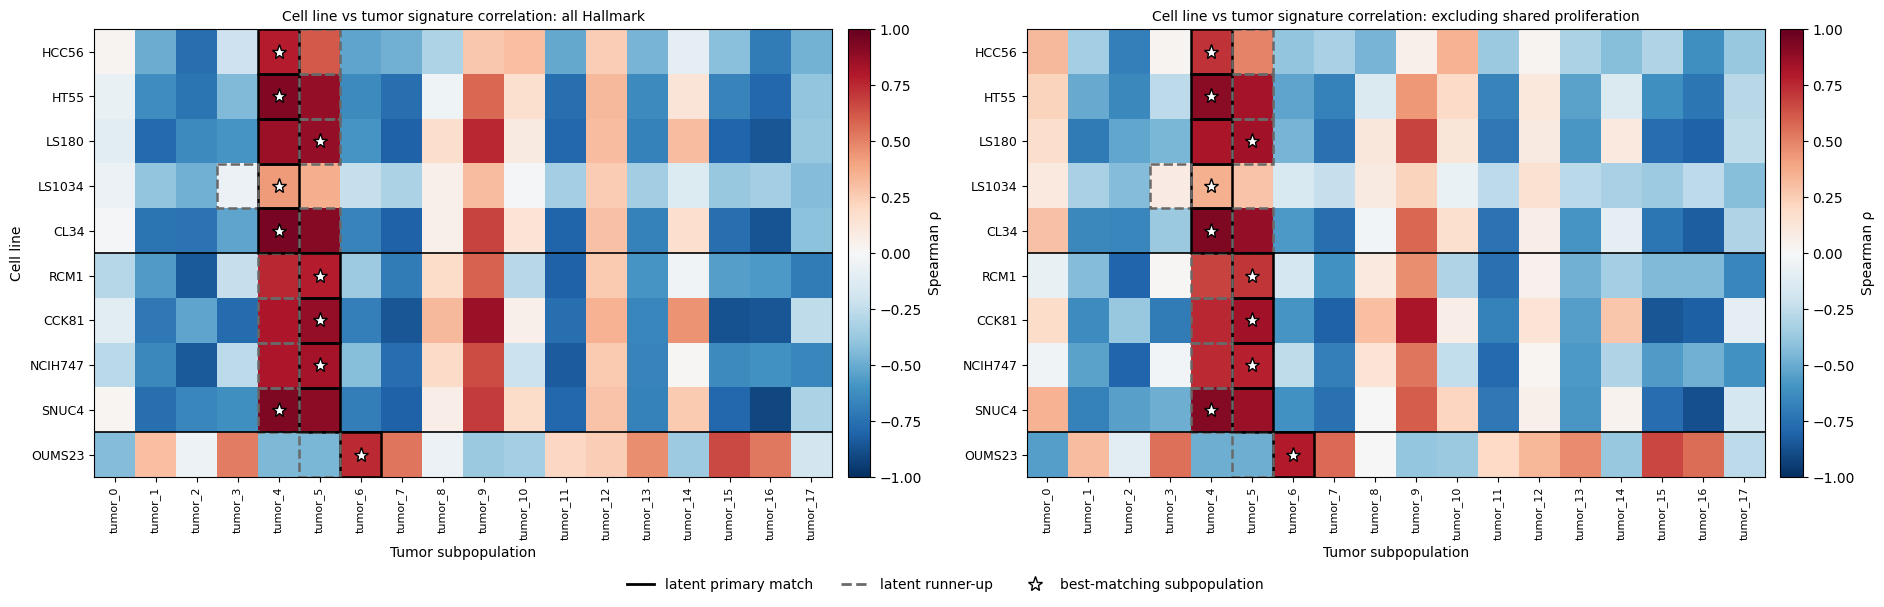

In [29]:
# Pathway-level match: correlate each cell line GSEA signature with each tumor signature.
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

gsea_line_labels = LINE_ORDER
gsea_tumor_labels = [group for group in TUMOR_ORDER if group in set(results_gsea_tumor["subpopulation"])]

line_signature = (
    results_gsea_line_vs_tumor
    .groupby(["cell_line", "pathway"], observed=True)["nes"]
    .mean()
    .unstack("pathway")
)
subpop_signature = (
    results_gsea_tumor
    .pivot_table(index="pathway", columns="subpopulation", values="nes")
)
signature_pathways = line_signature.columns.intersection(subpop_signature.index)
line_signature = line_signature.loc[gsea_line_labels, signature_pathways]
subpop_signature = subpop_signature.loc[signature_pathways, gsea_tumor_labels]

prolif_arm = ["tumor_4", "tumor_5", "tumor_12"]
prolif_shared = (
    results_gsea_tumor[
        results_gsea_tumor["subpopulation"].isin(prolif_arm)
        & results_gsea_tumor["fdr_qval"].le(0.05)
        & results_gsea_tumor["nes"].abs().ge(1.0)
    ]
    .groupby("pathway")["nes"]
    .apply(lambda values: len(values) == len(prolif_arm) and bool((values > 0).all()))
)
shared_proliferation = sorted(
    pathway for pathway, flag in prolif_shared.items() if bool(flag)
)


def signature_similarity(exclude=()):
    keep = [pathway for pathway in signature_pathways if pathway not in set(exclude)]
    return pd.DataFrame(
        {
            cell_line: {
                subpop: line_signature.loc[cell_line, keep].corr(
                    subpop_signature.loc[keep, subpop], method="spearman"
                )
                for subpop in gsea_tumor_labels
            }
            for cell_line in gsea_line_labels
        }
    ).T


signature_sets = {
    "all Hallmark": signature_similarity(),
    "excluding shared proliferation": signature_similarity(shared_proliferation),
}

readout_rows = []
for cell_line in gsea_line_labels:
    primary = str(line_matches.loc[cell_line, "primary_match"])
    runner_up = str(line_matches.loc[cell_line, "second_match"])
    record = {
        "cell_line": cell_line,
        "latent_primary": primary,
        "latent_runner_up": runner_up,
    }
    for name, similarity in signature_sets.items():
        order = similarity.loc[cell_line].sort_values(ascending=False)
        record[f"{name}: best"] = order.index[0]
        record[f"{name}: primary rank"] = int(order.index.get_loc(primary)) + 1
        record[f"{name}: runner-up rank"] = int(order.index.get_loc(runner_up)) + 1
    readout_rows.append(record)
signature_readout = pd.DataFrame(readout_rows)
display(signature_readout)

rng = np.random.default_rng(SEED)
null = rng.integers(1, len(gsea_tumor_labels) + 1, size=(1000, len(gsea_line_labels)))
for name in signature_sets:
    observed = signature_readout[f"{name}: primary rank"].to_numpy()
    p_value = float((np.median(null, axis=1) <= np.median(observed)).mean())
    print(
        f"{name}: median primary rank {np.median(observed):.1f} "
        f"(null {0.5 * (len(gsea_tumor_labels) + 1):.1f}), "
        f"top-1 rate {(observed == 1).mean():.0%}, permutation p = {p_value:.3f}"
    )

row_order_gsea = LINE_ORDER

fig, axes = plt.subplots(ncols=len(signature_sets), figsize=(9.5 * len(signature_sets), 5.8))
for ax, (name, similarity) in zip(axes, signature_sets.items()):
    values = similarity.loc[row_order_gsea, gsea_tumor_labels]
    image = ax.imshow(
        values.to_numpy(float), aspect="auto", cmap="RdBu_r",
        vmin=-1, vmax=1, interpolation="nearest",
    )
    ax.set_xticks(np.arange(len(gsea_tumor_labels)))
    ax.set_xticklabels(gsea_tumor_labels, rotation=90, fontsize=8)
    ax.set_yticks(np.arange(len(row_order_gsea)))
    ax.set_yticklabels(row_order_gsea, fontsize=9)
    ax.set_xlabel("Tumor subpopulation")
    ax.set_title(f"Cell line vs tumor signature correlation: {name}", fontsize=10)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.02).set_label("Spearman ρ")

    for y, cell_line in enumerate(row_order_gsea):
        for group, color, linestyle in [
            (str(line_matches.loc[cell_line, "primary_match"]), "black", "-"),
            (str(line_matches.loc[cell_line, "second_match"]), "dimgray", "--"),
        ]:
            if group in gsea_tumor_labels:
                x = gsea_tumor_labels.index(group)
                ax.add_patch(Rectangle(
                    (x - 0.5, y - 0.5), 1, 1, fill=False,
                    edgecolor=color, linewidth=1.8, linestyle=linestyle,
                ))
        best = values.loc[cell_line].idxmax()
        ax.plot(
            gsea_tumor_labels.index(best), y, marker="*", color="white",
            markeredgecolor="black", markersize=11, zorder=5,
        )

    previous_primary = None
    for y, cell_line in enumerate(row_order_gsea):
        primary = str(line_matches.loc[cell_line, "primary_match"])
        if previous_primary is not None and primary != previous_primary:
            ax.axhline(y - 0.5, color="black", linewidth=1.2)
        previous_primary = primary

axes[0].set_ylabel("Cell line")
fig.legend(
    handles=[
        Line2D([0], [0], color="black", lw=2, label="latent primary match"),
        Line2D([0], [0], color="dimgray", lw=2, linestyle="--", label="latent runner-up"),
        Line2D([0], [0], marker="*", color="white", markeredgecolor="black",
               linestyle="", markersize=11, label="best-matching subpopulation"),
    ],
    loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.05),
)
plt.tight_layout()
fig.savefig(FIG_DIR / "cl_tumor_gsea_signature_match.png", dpi=300, bbox_inches="tight")
plt.show()

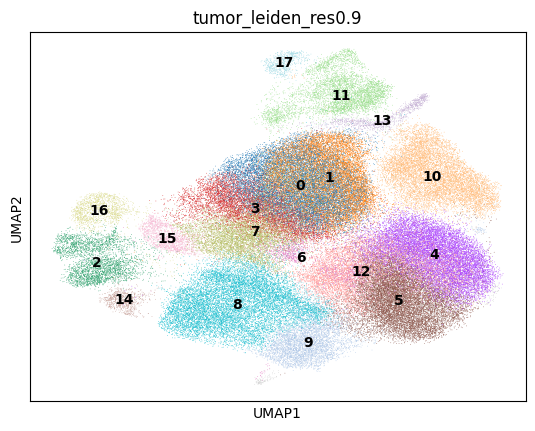

In [30]:
sc.pl.umap(combined_full, color=t_key, legend_loc="on data", na_in_legend=False)

In [31]:
shared_proliferation 

['E2F_TARGETS', 'G2M_CHECKPOINT', 'MITOTIC_SPINDLE', 'MYC_TARGETS_V1']

# Hallmark Pathway Scoring With MLM
Score all cells once on the 50 Hallmark pathways using the full available
Hallmark gene universe. Save the per-cell scores and reload them before
performing any group-level analysis.

In [32]:
import decoupler as dc

MLM_TMIN = 15
MLM_RAW = False
MLM_ARTIFACT_DIR = DE_DIR / "hallmark_mlm"
MLM_ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
MLM_ARTIFACT = MLM_ARTIFACT_DIR / "hallmark_mlm_scores.h5ad"
MLM_NETWORK = MLM_ARTIFACT_DIR / "hallmark_network.csv"
MLM_MANIFEST = MLM_ARTIFACT_DIR / "manifest.json"


all_genes = set(map(str, combined_full.var_names))
hallmark_net = pd.DataFrame([
    {"source": pathway, "target": gene, "weight": 1.0}
    for pathway, genes in hallmark_sets.items()
    for gene in sorted(set(map(str, genes)) & all_genes)
])

mlm_genes = sorted(set(hallmark_net["target"]) & all_genes)
assert combined_full.var_names.is_unique
assert set(mlm_genes) == set(hallmark_net["target"])
assert set(mlm_genes).issubset(all_genes)
assert hallmark_net["source"].nunique() == len(hallmark_sets)

def array_sha256(values):
    array = np.ascontiguousarray(values)
    return hashlib.sha256(array.tobytes()).hexdigest()

RECOMPUTE_MLM = False
if RECOMPUTE_MLM or not MLM_ARTIFACT.exists():
    adata_mlm = combined_full[:, mlm_genes].copy()

    dc.mt.mlm(
        data=adata_mlm,
        net=hallmark_net,
        tmin=MLM_TMIN,
        raw=MLM_RAW,
        verbose=False,
    )
    pathway_scores = adata_mlm.obsm["score_mlm"].copy()
    pathway_pvals = adata_mlm.obsm["padj_mlm"].copy()

    score_obs_to_save = combined_full.obs.loc[
        pathway_scores.index,
        ["dataset", "cell_line"],
    ].copy()

    score_obs_to_save["match_group"] = combined_full.obs.loc[
        pathway_scores.index, "match_group"
    ].astype("string")
    score_artifact = ad.AnnData(
        X=pathway_scores.to_numpy(dtype=np.float64),
        obs=score_obs_to_save,
        var=pd.DataFrame(index=pathway_scores.columns.astype(str)),
    )
    score_artifact.obsm["padj_mlm"] = pathway_pvals.to_numpy(dtype=np.float64)
    
    manifest = {
        "method": "decoupler.mt.mlm",
        "decoupler_version": getattr(dc, "__version__", "unknown"),
        "tmin": MLM_TMIN,
        "raw": MLM_RAW,
        "n_cells": int(pathway_scores.shape[0]),
        "n_pathways": int(pathway_scores.shape[1]),
        "n_genes": len(mlm_genes),
        "genes": mlm_genes,
        "pathways": list(map(str, pathway_scores.columns)),
        "score_sha256": array_sha256(pathway_scores.to_numpy(dtype=np.float64)),
        "padj_sha256": array_sha256(pathway_pvals.to_numpy(dtype=np.float64)),
    }
    
    score_artifact.uns["mlm_manifest"] = manifest
    score_artifact.write_h5ad(MLM_ARTIFACT, compression="gzip")
    hallmark_net.to_csv(MLM_NETWORK, index=False)
    MLM_MANIFEST.write_text(json.dumps(manifest, indent=2), encoding="utf-8")

    print(f"Computed and saved MLM artifact: {MLM_ARTIFACT}")
else:
    print(f"MLM artifact already exists; computation skipped: {MLM_ARTIFACT}")

print(f"MLM genes: {len(mlm_genes)}")
print(f"Pathways: {len(hallmark_sets)}")

MLM artifact already exists; computation skipped: /mnt/bigdisk/markus/CRC-scMFmap/models/validation/bio_joint_cfg10/de_signatures/hallmark_mlm/hallmark_mlm_scores.h5ad
MLM genes: 4237
Pathways: 50


In [33]:
mlm_artifact = ad.read_h5ad(MLM_ARTIFACT)

pathway_scores = pd.DataFrame(
    mlm_artifact.X,
    index=mlm_artifact.obs_names,
    columns=mlm_artifact.var_names,
)
pathway_pvals = pd.DataFrame(
    mlm_artifact.obsm["padj_mlm"],
    index=mlm_artifact.obs_names,
    columns=mlm_artifact.var_names,
)
score_obs = mlm_artifact.obs.copy()

assert pathway_scores.index.is_unique
assert pathway_scores.index.equals(score_obs.index)
assert pathway_scores.shape == pathway_pvals.shape
assert pathway_scores.notna().all().all()
assert pathway_pvals.notna().all().all()

print(f"Loaded MLM artifact: {MLM_ARTIFACT}")
print(f"Scored cells: {pathway_scores.shape[0]:,}")
print(f"Scored pathways: {pathway_scores.shape[1]}")
print(f"Scored genes: {len(mlm_artifact.uns['mlm_manifest']['genes'])}")

Loaded MLM artifact: /mnt/bigdisk/markus/CRC-scMFmap/models/validation/bio_joint_cfg10/de_signatures/hallmark_mlm/hallmark_mlm_scores.h5ad
Scored cells: 110,293
Scored pathways: 50
Scored genes: 4237


## Domain-aware MLM summaries
The MLM score matrix is computed once for all cells and then reloaded from the
saved artifact. The summaries below remain domain-specific: tumor subpopulations
and cell lines are aggregated separately. No domain normalization is applied.

In [34]:
score_obs = score_obs.copy()
score_obs["domain"] = score_obs["dataset"].astype(str)
score_obs["group"] = score_obs["match_group"].astype(str)

assert score_obs.index.equals(pathway_scores.index)
assert score_obs["domain"].isin(["tumor", "cell_line"]).all()

print("Scored cells:", len(score_obs))
print("Scored pathways:", pathway_scores.shape[1])
print(score_obs["domain"].value_counts())

Scored cells: 110293
Scored pathways: 50
domain
tumor        108131
cell_line      2162
Name: count, dtype: int64


In [35]:
score_table = pathway_scores.join(score_obs[["domain", "group"]])
pathway_columns = pathway_scores.columns.tolist()

group_scores = (
    score_table
    .groupby(["domain", "group"], observed=True)[pathway_columns]
    .median()
)

tumor_group_scores = group_scores.loc["tumor"].copy()
cell_line_group_scores = group_scores.loc["cell_line"].copy()

print("Tumor group score matrix:", tumor_group_scores.shape)
print("Cell line score matrix:", cell_line_group_scores.shape)
display(tumor_group_scores.head())
display(cell_line_group_scores.head())

Tumor group score matrix: (18, 50)
Cell line score matrix: (10, 50)


,ADIPOGENESIS,ALLOGRAFT_REJECTION,ANDROGEN_RESPONSE,ANGIOGENESIS,APICAL_JUNCTION,APICAL_SURFACE,APOPTOSIS,BILE_ACID_METABOLISM,CHOLESTEROL_HOMEOSTASIS,COAGULATION,...,PROTEIN_SECRETION,REACTIVE_OXYGEN_SPECIES_PATHWAY,SPERMATOGENESIS,TGF_BETA_SIGNALING,TNFA_SIGNALING_VIA_NFKB,UNFOLDED_PROTEIN_RESPONSE,UV_RESPONSE_DN,UV_RESPONSE_UP,WNT_BETA_CATENIN_SIGNALING,XENOBIOTIC_METABOLISM
group,,,,,,,,,,,,,,,,,,,,,
tumor_0,0.921278,1.205854,2.390597,-0.639900,0.365045,-0.957533,1.628501,-2.020097,2.429584,-0.874827,...,3.299595,4.068505,-2.587995,1.202327,1.537156,3.103553,-0.691702,0.211099,-1.395336,-0.825964
tumor_1,0.698777,1.237564,2.279391,-0.564794,0.230790,-0.991873,1.843182,-2.037697,1.960639,-0.947274,...,3.324422,3.863537,-2.505953,1.409832,2.021129,3.197492,-0.656766,0.370219,-0.979333,-1.101457
tumor_10,0.628106,1.056861,2.737170,-0.657542,0.522987,-0.959265,1.786380,-2.249661,2.285296,-0.878354,...,3.551918,3.711666,-2.789419,0.961041,1.902329,3.417408,-0.864375,0.509565,-1.391193,-0.895325
tumor_11,0.480249,1.161340,2.531345,-0.509851,0.546042,-0.729821,1.510193,-1.652946,1.924951,-0.482238,...,3.159221,2.620870,-2.283449,0.655527,1.319124,2.534824,-0.642464,0.193898,-1.216203,-0.728803
tumor_12,0.662954,1.140594,2.121379,-0.377404,0.427841,-0.802737,1.447361,-1.798931,1.820320,-1.024642,...,2.432368,3.049587,-2.327600,0.885732,0.276305,2.710774,-0.895087,0.293481,-1.091882,-0.883592


,ADIPOGENESIS,ALLOGRAFT_REJECTION,ANDROGEN_RESPONSE,ANGIOGENESIS,APICAL_JUNCTION,APICAL_SURFACE,APOPTOSIS,BILE_ACID_METABOLISM,CHOLESTEROL_HOMEOSTASIS,COAGULATION,...,PROTEIN_SECRETION,REACTIVE_OXYGEN_SPECIES_PATHWAY,SPERMATOGENESIS,TGF_BETA_SIGNALING,TNFA_SIGNALING_VIA_NFKB,UNFOLDED_PROTEIN_RESPONSE,UV_RESPONSE_DN,UV_RESPONSE_UP,WNT_BETA_CATENIN_SIGNALING,XENOBIOTIC_METABOLISM
group,,,,,,,,,,,,,,,,,,,,,
line_CCK81,1.121352,0.543141,1.204200,-0.729917,-0.163970,-1.578179,1.056891,-2.205989,1.762866,-0.955906,...,2.780541,6.069692,-2.382156,1.210738,-0.755658,4.171201,-1.747581,1.084929,-1.397887,-0.485658
line_CL34,0.161285,0.839356,2.250175,-0.362257,0.273114,-1.405370,1.543286,-2.453560,1.592300,-1.283731,...,2.443145,3.487324,-2.380329,0.738130,-0.682417,3.718596,-1.155307,0.606935,-1.397660,-1.419349
line_HCC56,0.127459,0.824489,2.331544,-0.840801,0.866388,-1.062901,2.180630,-2.332622,1.411154,-1.322872,...,2.921376,3.681108,-2.654681,0.784075,1.131833,3.454055,-1.179078,0.892551,-1.560062,-1.866855
line_HT55,0.400930,0.274245,2.852839,-0.964611,0.597635,-1.298063,1.393980,-2.450892,1.459205,-1.133058,...,3.404720,3.674263,-2.302780,2.063945,0.895075,2.993846,-1.180109,0.891336,-0.998961,-1.462928
line_LS1034,0.104269,0.988051,2.282268,-0.247792,1.088595,-0.733360,1.950960,-2.040600,1.577712,-0.666833,...,2.387939,3.756351,-2.782203,1.724156,0.304601,2.687264,-1.440002,-0.094313,-1.020379,-1.645062


In [36]:
group_score_summary = (
    score_table
    .groupby(["domain", "group"], observed=True)[pathway_columns]
    .agg(["median", "mean", "std"])
)
group_score_summary.insert(
    0,
    "n_cells",
    score_obs.groupby(["domain", "group"], observed=True).size(),
)
group_score_summary.head()

n_cells ADIPOGENESIS                      \
                                    median      mean       std   
domain    group                                                  
cell_line line_CCK81      127     1.121352  1.129460  0.565357   
          line_CL34       418     0.161285  0.185144  0.665750   
          line_HCC56      102     0.127459  0.134509  0.587508   
          line_HT55       211     0.400930  0.446272  0.689346   
          line_LS1034     153     0.104269  0.120404  0.591053   

                      ALLOGRAFT_REJECTION                      \
                                   median      mean       std   
domain    group                                                 
cell_line line_CCK81             0.543141  0.581654  0.418371   
          line_CL34              0.839356  0.847659  0.464352   
          line_HCC56             0.824489  0.812383  0.553077   
          line_HT55              0.274245  0.367737  0.508738   
          line_LS1034            0.988051  1.029940  0.570804   

                      ANDROGEN_RESPONSE                      ...  \
                                 median      mean       std  ...   
domain    group                                              ...   
cell_line line_CCK81           1.204200  1.206263  0.518024  ...   
          line_CL34            2.250175  2.260994  0.708612  ...   
          line_HCC56           2.331544  2.251824  0.695217  ...   
          line_HT55            2.852839  2.864468  0.702750  ...   
          line_LS1034          2.282268  2.331187  0.678563  ...   

                      UV_RESPONSE_DN UV_RESPONSE_UP                      \
                                 std         median      mean       std   
domain    group                                                           
cell_line line_CCK81        0.447322       1.084929  1.025613  0.623683   
          line_CL34         0.608440       0.606935  0.589514  0.725830   
          line_HCC56        0.584966       0.892551  0.799693  0.785176   
          line_HT55         0.586260       0.891336  0.916120  0.675952   
          line_LS1034       0.538138      -0.094313 -0.094924  0.681467   

                      WNT_BETA_CATENIN_SIGNALING                      \
                                          median      mean       std   
domain    group                                                        
cell_line line_CCK81                   -1.397887 -1.382929  0.451982   
          line_CL34                    -1.397660 -1.350093  0.607076   
          line_HCC56                   -1.560062 -1.512917  0.669594   
          line_HT55                    -0.998961 -0.900227  0.692361   
          line_LS1034                  -1.020379 -0.971519  0.677919   

                      XENOBIOTIC_METABOLISM                      
                                     median      mean       std  
domain    group                                                  
cell_line line_CCK81              -0.485658 -0.494319  0.579503  
          line_CL34               -1.419349 -1.388755  0.587232  
          line_HCC56              -1.866855 -1.844296  0.552491  
          line_HT55               -1.462928 -1.418022  0.571112  
          line_LS1034             -1.645062 -1.630221  0.522450  

[5 rows x 151 columns]

In [37]:
# This is descriptive only.
# It shows whether the two domains have broad score shifts.
domain_medians = (
    score_table
    .groupby("domain", observed=True)[pathway_columns]
    .median()
    .T
)
domain_medians["cell_line_minus_tumor"] = domain_medians["cell_line"] - domain_medians["tumor"]
domain_medians.sort_values("cell_line_minus_tumor")

domain,cell_line,tumor,cell_line_minus_tumor
INTERFERON_ALPHA_RESPONSE,0.306057,1.811562,-1.505505
TNFA_SIGNALING_VIA_NFKB,-0.312012,1.158100,-1.470113
KRAS_SIGNALING_UP,-2.896283,-1.796421,-1.099862
INTERFERON_GAMMA_RESPONSE,-1.591221,-0.533528,-1.057693
HYPOXIA,-0.396597,0.521033,-0.917631
KRAS_SIGNALING_DN,-4.814307,-4.121847,-0.692460
BILE_ACID_METABOLISM,-2.542208,-1.917357,-0.624851
ALLOGRAFT_REJECTION,0.645342,1.181456,-0.536114
ESTROGEN_RESPONSE_LATE,0.613150,1.123561,-0.510411
UV_RESPONSE_DN,-1.302239,-0.818991,-0.483248


## Per-cell distributions and group summaries
The primary group score is the median of the per-cell MLM scores. Quantiles are
retained to show within-group heterogeneity. The raw per-cell scores remain the
primary data and are not standardized across domains.

In [38]:
distribution_rows = []

for (domain, group), group_obs in score_obs.groupby(
    ["domain", "group"],
    observed=True,
):
    group_scores = pathway_scores.loc[group_obs.index]

    for pathway in pathway_scores.columns:
        values = group_scores[pathway].dropna()

        distribution_rows.append({
            "domain": domain,
            "group": group,
            "pathway": pathway,
            "n_cells": values.size,
            "mean": values.mean(),
            "std": values.std(),
            "q05": values.quantile(0.05),
            "q25": values.quantile(0.25),
            "median": values.median(),
            "q75": values.quantile(0.75),
            "q95": values.quantile(0.95),
        })

group_score_distributions = pd.DataFrame(distribution_rows)

print(group_score_distributions.shape)
group_score_distributions.head()

(1400, 11)


,domain,group,pathway,n_cells,mean,std,q05,q25,median,q75,q95
0,cell_line,line_CCK81,ADIPOGENESIS,127,1.129460,0.565357,0.251519,0.819835,1.121352,1.414504,2.078899
1,cell_line,line_CCK81,ALLOGRAFT_REJECTION,127,0.581654,0.418371,-0.059974,0.281638,0.543141,0.857907,1.275621
2,cell_line,line_CCK81,ANDROGEN_RESPONSE,127,1.206263,0.518024,0.330474,0.876790,1.204200,1.550626,1.952338
3,cell_line,line_CCK81,ANGIOGENESIS,127,-0.740100,0.319606,-1.264765,-0.936346,-0.729917,-0.548814,-0.231256
4,cell_line,line_CCK81,APICAL_JUNCTION,127,-0.145437,0.435838,-0.871666,-0.477716,-0.163970,0.105210,0.624701


In [39]:
tumor_score_distributions = (
    group_score_distributions
    .query("domain == 'tumor'")
    .copy()
)
cell_line_score_distributions = (
    group_score_distributions
    .query("domain == 'cell_line'")
    .copy()
)

display(tumor_score_distributions.head())
display(cell_line_score_distributions.head())

,domain,group,pathway,n_cells,mean,std,q05,q25,median,q75,q95
500,tumor,tumor_0,ADIPOGENESIS,12126,0.922754,0.787389,-0.371878,0.412162,0.921278,1.432077,2.212732
501,tumor,tumor_0,ALLOGRAFT_REJECTION,12126,1.220563,0.688584,0.119860,0.763064,1.205854,1.657938,2.382205
502,tumor,tumor_0,ANDROGEN_RESPONSE,12126,2.425114,0.972584,0.876399,1.783182,2.390597,3.034922,4.090622
503,tumor,tumor_0,ANGIOGENESIS,12126,-0.589018,0.504128,-1.332798,-0.934436,-0.639900,-0.296933,0.314478
504,tumor,tumor_0,APICAL_JUNCTION,12126,0.396345,0.660411,-0.622035,-0.059010,0.365045,0.805374,1.544041


,domain,group,pathway,n_cells,mean,std,q05,q25,median,q75,q95
0,cell_line,line_CCK81,ADIPOGENESIS,127,1.129460,0.565357,0.251519,0.819835,1.121352,1.414504,2.078899
1,cell_line,line_CCK81,ALLOGRAFT_REJECTION,127,0.581654,0.418371,-0.059974,0.281638,0.543141,0.857907,1.275621
2,cell_line,line_CCK81,ANDROGEN_RESPONSE,127,1.206263,0.518024,0.330474,0.876790,1.204200,1.550626,1.952338
3,cell_line,line_CCK81,ANGIOGENESIS,127,-0.740100,0.319606,-1.264765,-0.936346,-0.729917,-0.548814,-0.231256
4,cell_line,line_CCK81,APICAL_JUNCTION,127,-0.145437,0.435838,-0.871666,-0.477716,-0.163970,0.105210,0.624701


In [40]:
tumor_group_scores = (
    tumor_score_distributions
    .pivot(
        index="group",
        columns="pathway",
        values="median",
    )
)
cell_line_group_scores = (
    cell_line_score_distributions
    .pivot(
        index="group",
        columns="pathway",
        values="median",
    )
)

print("Tumor score matrix:", tumor_group_scores.shape)
print("Cell line score matrix:", cell_line_group_scores.shape)
display(tumor_group_scores)
display(cell_line_group_scores)

Tumor score matrix: (18, 50)
Cell line score matrix: (10, 50)


pathway,ADIPOGENESIS,ALLOGRAFT_REJECTION,ANDROGEN_RESPONSE,ANGIOGENESIS,APICAL_JUNCTION,APICAL_SURFACE,APOPTOSIS,BILE_ACID_METABOLISM,CHOLESTEROL_HOMEOSTASIS,COAGULATION,...,PROTEIN_SECRETION,REACTIVE_OXYGEN_SPECIES_PATHWAY,SPERMATOGENESIS,TGF_BETA_SIGNALING,TNFA_SIGNALING_VIA_NFKB,UNFOLDED_PROTEIN_RESPONSE,UV_RESPONSE_DN,UV_RESPONSE_UP,WNT_BETA_CATENIN_SIGNALING,XENOBIOTIC_METABOLISM
group,,,,,,,,,,,,,,,,,,,,,
tumor_0,0.921278,1.205854,2.390597,-0.639900,0.365045,-0.957533,1.628501,-2.020097,2.429584,-0.874827,...,3.299595,4.068505,-2.587995,1.202327,1.537156,3.103553,-0.691702,0.211099,-1.395336,-0.825964
tumor_1,0.698777,1.237564,2.279391,-0.564794,0.230790,-0.991873,1.843182,-2.037697,1.960639,-0.947274,...,3.324422,3.863537,-2.505953,1.409832,2.021129,3.197492,-0.656766,0.370219,-0.979333,-1.101457
tumor_10,0.628106,1.056861,2.737170,-0.657542,0.522987,-0.959265,1.786380,-2.249661,2.285296,-0.878354,...,3.551918,3.711666,-2.789419,0.961041,1.902329,3.417408,-0.864375,0.509565,-1.391193,-0.895325
tumor_11,0.480249,1.161340,2.531345,-0.509851,0.546042,-0.729821,1.510193,-1.652946,1.924951,-0.482238,...,3.159221,2.620870,-2.283449,0.655527,1.319124,2.534824,-0.642464,0.193898,-1.216203,-0.728803
tumor_12,0.662954,1.140594,2.121379,-0.377404,0.427841,-0.802737,1.447361,-1.798931,1.820320,-1.024642,...,2.432368,3.049587,-2.327600,0.885732,0.276305,2.710774,-0.895087,0.293481,-1.091882,-0.883592
tumor_13,0.465063,0.691138,2.301529,-0.381999,0.444150,-0.920886,1.651444,-1.648716,1.545916,-0.451489,...,2.988079,3.785484,-2.175526,1.089073,1.654539,2.625146,-0.942921,0.489486,-1.362962,-1.169707
tumor_14,1.571391,0.975161,2.671129,-0.745929,0.398029,-0.992874,1.373462,-2.056947,2.403455,-1.399115,...,3.362289,3.837924,-2.722499,1.156740,0.773446,2.599898,-0.737692,0.368759,-1.679834,-0.287783
tumor_15,-0.041140,0.014880,1.403344,-0.392204,0.642910,-0.449036,1.677850,-0.830200,0.784393,-0.849734,...,1.045431,0.594910,-1.251150,0.897872,2.812054,1.349784,0.087801,0.588198,-0.445986,-0.684740
tumor_16,1.337108,-0.148555,3.582969,-0.699526,2.059175,-0.374680,2.495094,-1.178354,1.412730,-0.505765,...,2.763888,1.897207,-2.234856,1.791123,2.751403,0.824621,-0.573519,0.760003,-1.090887,0.168487


pathway,ADIPOGENESIS,ALLOGRAFT_REJECTION,ANDROGEN_RESPONSE,ANGIOGENESIS,APICAL_JUNCTION,APICAL_SURFACE,APOPTOSIS,BILE_ACID_METABOLISM,CHOLESTEROL_HOMEOSTASIS,COAGULATION,...,PROTEIN_SECRETION,REACTIVE_OXYGEN_SPECIES_PATHWAY,SPERMATOGENESIS,TGF_BETA_SIGNALING,TNFA_SIGNALING_VIA_NFKB,UNFOLDED_PROTEIN_RESPONSE,UV_RESPONSE_DN,UV_RESPONSE_UP,WNT_BETA_CATENIN_SIGNALING,XENOBIOTIC_METABOLISM
group,,,,,,,,,,,,,,,,,,,,,
line_CCK81,1.121352,0.543141,1.204200,-0.729917,-0.163970,-1.578179,1.056891,-2.205989,1.762866,-0.955906,...,2.780541,6.069692,-2.382156,1.210738,-0.755658,4.171201,-1.747581,1.084929,-1.397887,-0.485658
line_CL34,0.161285,0.839356,2.250175,-0.362257,0.273114,-1.405370,1.543286,-2.453560,1.592300,-1.283731,...,2.443145,3.487324,-2.380329,0.738130,-0.682417,3.718596,-1.155307,0.606935,-1.397660,-1.419349
line_HCC56,0.127459,0.824489,2.331544,-0.840801,0.866388,-1.062901,2.180630,-2.332622,1.411154,-1.322872,...,2.921376,3.681108,-2.654681,0.784075,1.131833,3.454055,-1.179078,0.892551,-1.560062,-1.866855
line_HT55,0.400930,0.274245,2.852839,-0.964611,0.597635,-1.298063,1.393980,-2.450892,1.459205,-1.133058,...,3.404720,3.674263,-2.302780,2.063945,0.895075,2.993846,-1.180109,0.891336,-0.998961,-1.462928
line_LS1034,0.104269,0.988051,2.282268,-0.247792,1.088595,-0.733360,1.950960,-2.040600,1.577712,-0.666833,...,2.387939,3.756351,-2.782203,1.724156,0.304601,2.687264,-1.440002,-0.094313,-1.020379,-1.645062
line_LS180,0.409874,0.574991,1.999956,-1.018960,-0.020278,-1.322990,1.474296,-2.613920,1.493573,-1.284475,...,2.915915,4.669339,-2.628050,1.137480,-0.118423,3.780639,-1.156871,0.323948,-1.530887,-1.199830
line_NCIH747,-0.046611,0.723419,1.709854,-1.227215,0.695807,-0.412419,2.344555,-2.845918,1.315068,-0.551056,...,3.104458,5.187563,-2.911684,1.010824,0.522647,2.975158,-1.059494,0.357845,-2.035482,-1.861885
line_OUMS23,0.879598,-0.389263,3.135809,-0.955063,1.790839,-1.117436,1.490785,-2.973528,2.578544,-0.868306,...,3.251036,4.275593,-3.321407,1.648502,-0.121119,3.772617,-1.509795,1.357687,-1.467582,-1.405549
line_RCM1,0.525047,1.247767,2.202022,-0.963927,0.424771,-1.176670,1.850551,-2.736432,1.804203,-0.461813,...,2.586463,4.861786,-2.832968,0.710879,-0.319688,3.656755,-1.729672,1.031004,-2.019004,-1.460816


In [41]:
domain_distribution_rows = []

for domain, domain_obs in score_obs.groupby("domain", observed=True):
    domain_scores = pathway_scores.loc[domain_obs.index]

    for pathway in pathway_scores.columns:
        values = domain_scores[pathway].dropna()

        domain_distribution_rows.append({
            "domain": domain,
            "pathway": pathway,
            "n_cells": values.size,
            "q05": values.quantile(0.05),
            "q25": values.quantile(0.25),
            "median": values.median(),
            "q75": values.quantile(0.75),
            "q95": values.quantile(0.95),
        })

domain_score_distributions = pd.DataFrame(domain_distribution_rows)
domain_score_distributions.head()

,domain,pathway,n_cells,q05,q25,median,q75,q95
0,cell_line,ADIPOGENESIS,2162,-0.615651,-0.022088,0.453679,0.896633,1.572861
1,cell_line,ALLOGRAFT_REJECTION,2162,-0.310648,0.264083,0.645342,1.010002,1.588101
2,cell_line,ANDROGEN_RESPONSE,2162,0.756279,1.482751,2.029257,2.613926,3.517726
3,cell_line,ANGIOGENESIS,2162,-1.522437,-1.105258,-0.796660,-0.430528,0.224693
4,cell_line,APICAL_JUNCTION,2162,-0.766781,-0.196026,0.271260,0.786807,1.812168


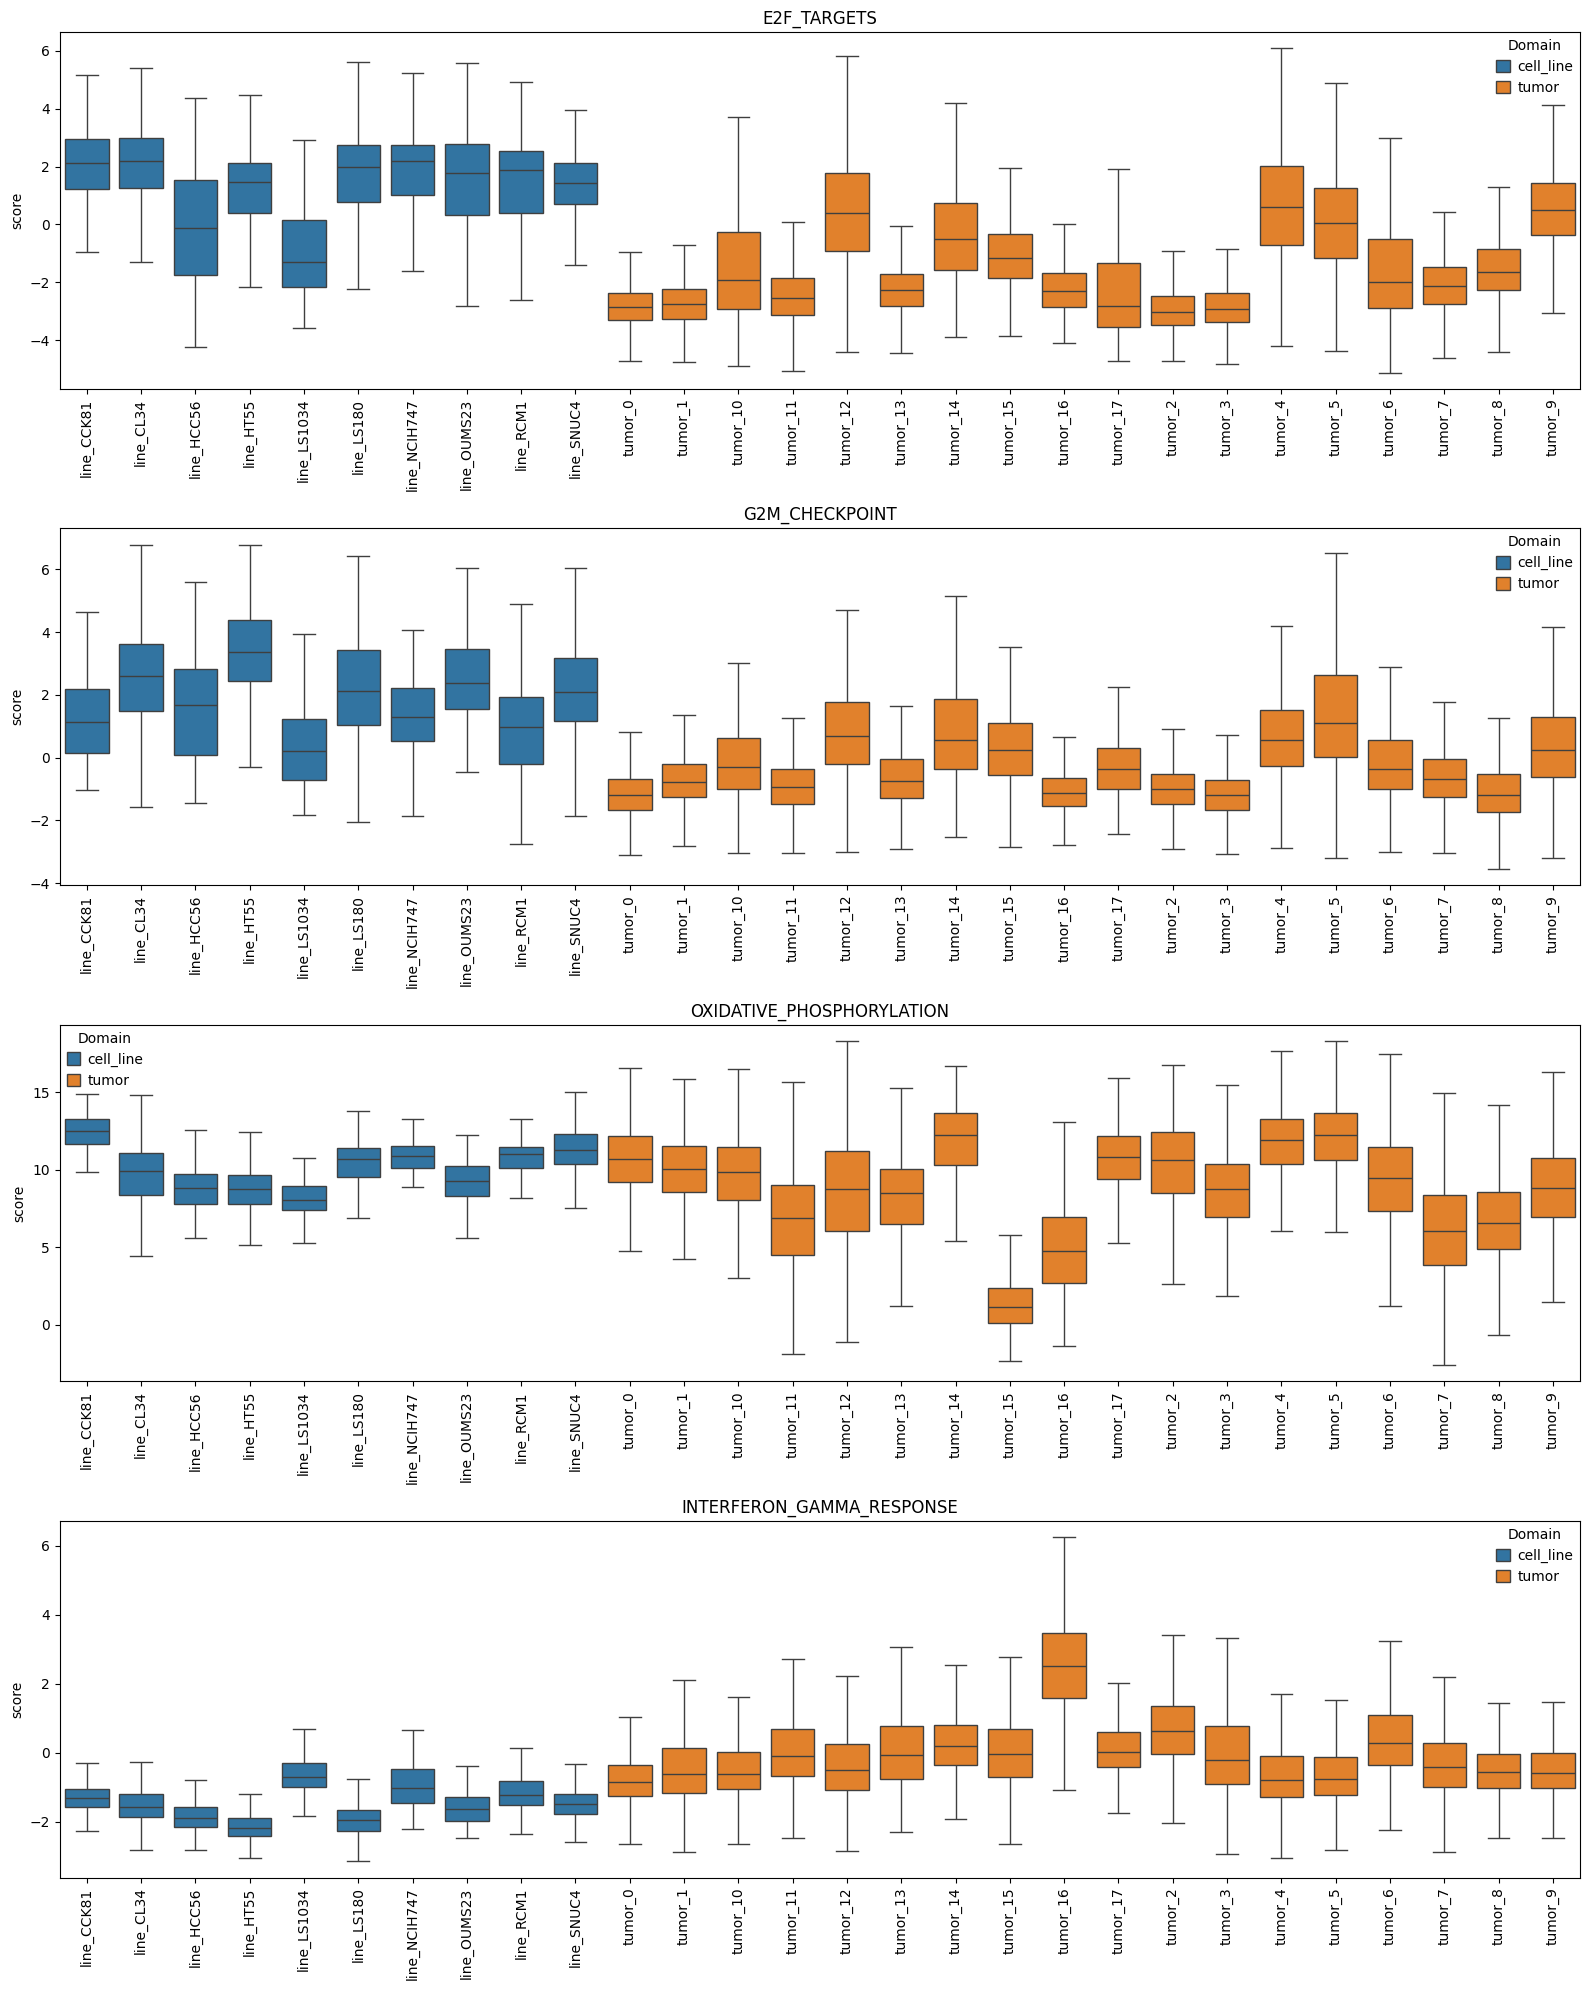

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_pathways = [
    "E2F_TARGETS",
    "G2M_CHECKPOINT",
    "OXIDATIVE_PHOSPHORYLATION",
    "INTERFERON_GAMMA_RESPONSE",
]

plot_pathways = [
    pathway
    for pathway in plot_pathways
    if pathway in pathway_scores.columns
]

plot_rows = []

for pathway in plot_pathways:
    for (domain, group), group_obs in score_obs.groupby(
        ["domain", "group"],
        observed=True,
    ):
        values = pathway_scores.loc[group_obs.index, pathway]

        plot_rows.extend({
            "domain": domain,
            "group": group,
            "pathway": pathway,
            "score": value,
        } for value in values.dropna())

plot_data = pd.DataFrame(plot_rows)

fig, axes = plt.subplots(
    nrows=len(plot_pathways),
    ncols=1,
    figsize=(16, 5 * len(plot_pathways)),
    squeeze=False,
)

for ax, pathway in zip(axes[:, 0], plot_pathways):
    subset = plot_data.loc[plot_data["pathway"].eq(pathway)]

    sns.boxplot(
        data=subset,
        x="group",
        y="score",
        hue="domain",
        dodge=False,
        showfliers=False,
        ax=ax,
    )

    ax.set_title(pathway)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=90)
    ax.legend(title="Domain")

plt.tight_layout()
plt.show()

## MLM delta on the tumor subpop

In [43]:
# Tumor-only MLM contrasts:
# tumor subpopulation median minus the median of the remaining tumor cells.

tumor_mask_mlm = (
    combined_full.obs.loc[pathway_scores.index, "dataset"]
    .astype(str)
    .eq("tumor")
)

tumor_groups_mlm = (
    combined_full.obs.loc[pathway_scores.index, "match_group"]
    .astype(str)
)

tumor_contrast_rows = []

for subpopulation in sorted(
    tumor_groups_mlm.loc[tumor_mask_mlm].unique()
):
    source_mask = (
        tumor_mask_mlm
        & tumor_groups_mlm.eq(subpopulation)
    )

    rest_mask = (
        tumor_mask_mlm
        & ~tumor_groups_mlm.eq(subpopulation)
    )

    source_scores = pathway_scores.loc[source_mask]
    rest_scores = pathway_scores.loc[rest_mask]

    for pathway in pathway_scores.columns:
        source_median = source_scores[pathway].median()
        rest_median = rest_scores[pathway].median()

        tumor_contrast_rows.append({
            "subpopulation": subpopulation,
            "pathway": pathway,
            "source_median_mlm": source_median,
            "rest_median_mlm": rest_median,
            "mlm_delta": source_median - rest_median,
            "n_source": source_scores[pathway].notna().sum(),
            "n_rest": rest_scores[pathway].notna().sum(),
        })

tumor_mlm_contrasts = pd.DataFrame(tumor_contrast_rows)

display(tumor_mlm_contrasts.head())

,subpopulation,pathway,source_median_mlm,rest_median_mlm,mlm_delta,n_source,n_rest
0,tumor_0,ADIPOGENESIS,0.921278,0.640708,0.280570,12126,96005
1,tumor_0,ALLOGRAFT_REJECTION,1.205854,1.177048,0.028806,12126,96005
2,tumor_0,ANDROGEN_RESPONSE,2.390597,2.306457,0.084141,12126,96005
3,tumor_0,ANGIOGENESIS,-0.639900,-0.596510,-0.043390,12126,96005
4,tumor_0,APICAL_JUNCTION,0.365045,0.360589,0.004455,12126,96005


In [44]:
# Compare the signed MLM contrast with signed GSEA NES.
# These values should not be expected to be numerically identical.
# We are checking directional and rank agreement.

gsea_comparison = (
    results_gsea_tumor[
        ["subpopulation", "pathway", "nes", "fdr_qval"]
    ]
    .copy()
)

mlm_gsea_comparison = tumor_mlm_contrasts.merge(
    gsea_comparison,
    on=["subpopulation", "pathway"],
    how="inner",
)

mlm_gsea_comparison["same_direction"] = (
    np.sign(mlm_gsea_comparison["mlm_delta"])
    == np.sign(mlm_gsea_comparison["nes"])
)

directional_agreement = (
    mlm_gsea_comparison["same_direction"]
    .mean()
)

rank_correlation = (
    mlm_gsea_comparison[
        ["mlm_delta", "nes"]
    ]
    .corr(method="spearman")
    .loc["mlm_delta", "nes"]
)

print(
    "Directional agreement:",
    f"{directional_agreement:.1%}",
)

print(
    "Spearman correlation:",
    f"{rank_correlation:.3f}",
)

display(
    mlm_gsea_comparison[
        [
            "subpopulation",
            "pathway",
            "mlm_delta",
            "nes",
            "fdr_qval",
            "same_direction",
        ]
    ]
    .sort_values(
        ["subpopulation", "mlm_delta"],
        ascending=[True, False],
    )
)

Directional agreement: 68.3%
Spearman correlation: 0.496


,subpopulation,pathway,mlm_delta,nes,fdr_qval,same_direction
30,tumor_0,MYC_TARGETS_V1,1.626858,-2.114169,0.000000,False
32,tumor_0,OXIDATIVE_PHOSPHORYLATION,1.275385,1.429728,0.146209,True
40,tumor_0,TNFA_SIGNALING_VIA_NFKB,0.438746,-1.219203,0.338269,False
37,tumor_0,REACTIVE_OXYGEN_SPECIES_PATHWAY,0.419945,0.801801,0.885890,True
33,tumor_0,P53_PATHWAY,0.375882,1.228843,0.224139,True
...,...,...,...,...,...,...
771,tumor_9,APOPTOSIS,-0.919513,-1.016055,0.584704,True
767,tumor_9,ANDROGEN_RESPONSE,-1.045218,-1.156173,0.364522,True
798,tumor_9,P53_PATHWAY,-1.304638,-1.052173,0.539376,True
806,tumor_9,UNFOLDED_PROTEIN_RESPONSE,-1.353802,0.706226,1.000000,False


## Cell-line/tumor MLM concordance
These plots compare pathway-score profiles for whole cell lines with tumor subpopulations and quantify primary-versus-runner-up specificity.

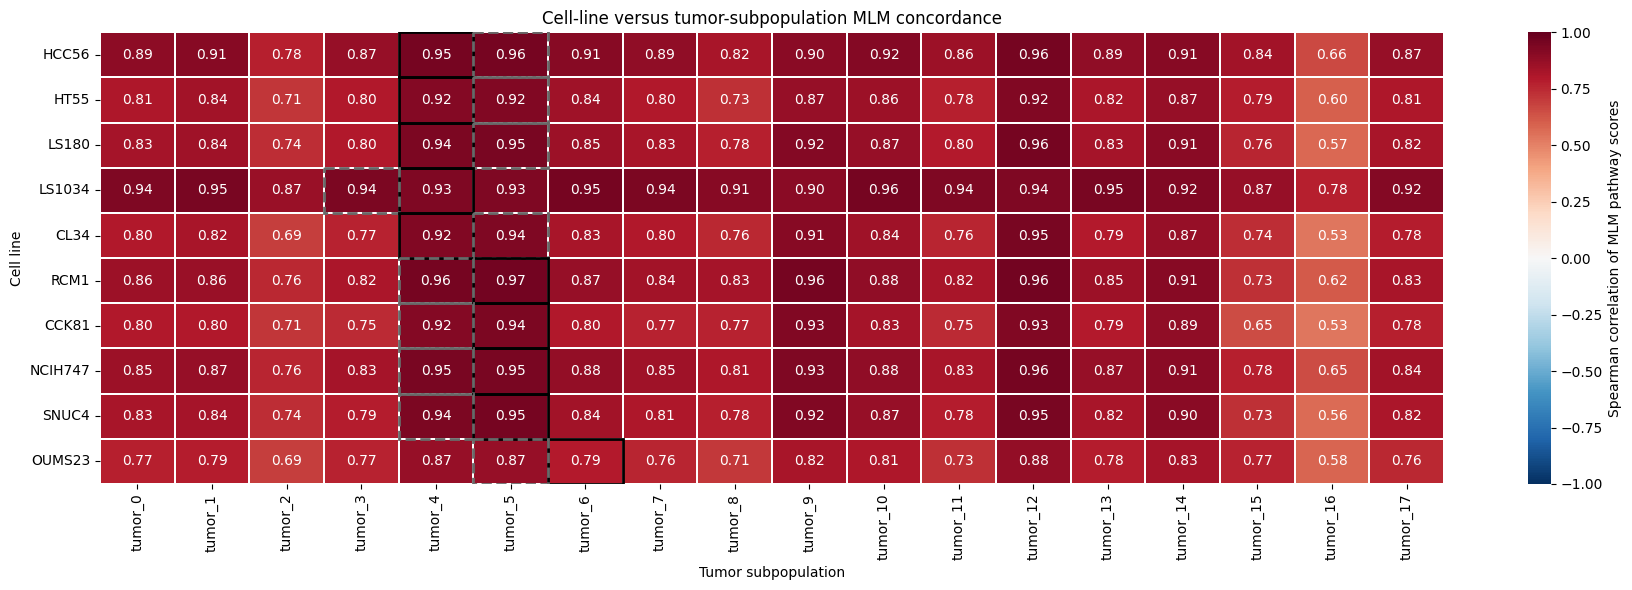

,cell_line,primary_match,runner_up,primary_rho,runner_up_rho,primary_minus_runner_up
0,OUMS23,tumor_6,tumor_5,0.792,0.875,-0.083
1,LS1034,tumor_4,tumor_3,0.931,0.944,-0.013
2,CL34,tumor_4,tumor_5,0.923,0.936,-0.013
3,LS180,tumor_4,tumor_5,0.943,0.951,-0.008
4,HT55,tumor_4,tumor_5,0.917,0.923,-0.006
5,HCC56,tumor_4,tumor_5,0.955,0.960,-0.005
6,NCIH747,tumor_5,tumor_4,0.952,0.952,-0.000
7,RCM1,tumor_5,tumor_4,0.966,0.958,0.008
8,SNUC4,tumor_5,tumor_4,0.954,0.942,0.012
9,CCK81,tumor_5,tumor_4,0.942,0.922,0.021


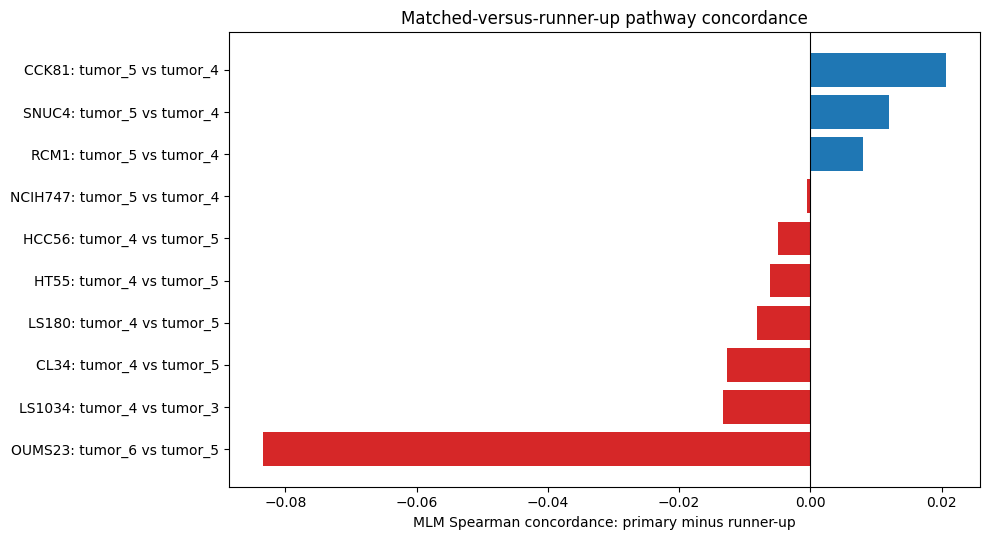

In [45]:
# Cell-line/tumor pathway concordance and matched-versus-runner-up specificity.
cell_scores_concordance = cell_line_group_scores.copy()
cell_scores_concordance.index = cell_scores_concordance.index.str.replace(
    "^line_", "", regex=True
)
tumor_scores_concordance = tumor_group_scores.copy()
line_order = LINE_ORDER
tumor_order = [group for group in TUMOR_ORDER if group in set(tumor_scores_concordance.index)]

mlm_concordance = pd.DataFrame(index=line_order, columns=tumor_order, dtype=float)
for cell_line in line_order:
    for tumor_group in tumor_order:
        mlm_concordance.loc[cell_line, tumor_group] = (
            cell_scores_concordance.loc[cell_line]
            .corr(tumor_scores_concordance.loc[tumor_group], method="spearman")
        )

fig, ax = plt.subplots(figsize=(18, 6))
sns.heatmap(
    mlm_concordance,
    ax=ax,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    linewidths=0.3,
    cbar_kws={"label": "Spearman correlation of MLM pathway scores"},
)
for y, cell_line in enumerate(line_order):
    for group, color, linestyle in [
        (line_matches.loc[cell_line, "primary_match"], "black", "-"),
        (line_matches.loc[cell_line, "second_match"], "dimgray", "--"),
    ]:
        if group in tumor_order:
            x = tumor_order.index(group)
            ax.add_patch(
                Rectangle(
                    (x, y), 1, 1, fill=False, edgecolor=color,
                    linewidth=2.0, linestyle=linestyle,
                )
            )
ax.set_title("Cell-line versus tumor-subpopulation MLM concordance")
ax.set_xlabel("Tumor subpopulation")
ax.set_ylabel("Cell line")
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
plt.tight_layout()
fig.savefig(FIG_DIR / "mlm_concordance.png", dpi=300, bbox_inches="tight")
plt.show()

runner_up_rows = []
for cell_line in line_order:
    primary = str(line_matches.loc[cell_line, "primary_match"])
    runner_up = str(line_matches.loc[cell_line, "second_match"])
    primary_rho = float(mlm_concordance.loc[cell_line, primary])
    runner_up_rho = float(mlm_concordance.loc[cell_line, runner_up])
    runner_up_rows.append({
        "cell_line": cell_line,
        "primary_match": primary,
        "runner_up": runner_up,
        "primary_rho": primary_rho,
        "runner_up_rho": runner_up_rho,
        "primary_minus_runner_up": primary_rho - runner_up_rho,
    })

matched_runner_up = (
    pd.DataFrame(runner_up_rows)
    .sort_values("primary_minus_runner_up")
    .reset_index(drop=True)
)
display(matched_runner_up.round(3))

fig, ax = plt.subplots(figsize=(10, 5.5))
colors = np.where(
    matched_runner_up["primary_minus_runner_up"] >= 0,
    "tab:blue",
    "tab:red",
)
labels = (
    matched_runner_up["cell_line"]
    + ": "
    + matched_runner_up["primary_match"]
    + " vs "
    + matched_runner_up["runner_up"]
)
ax.barh(labels, matched_runner_up["primary_minus_runner_up"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("MLM Spearman concordance: primary minus runner-up")
ax.set_ylabel("")
ax.set_title("Matched-versus-runner-up pathway concordance")
plt.tight_layout()
plt.show()

# test

In [46]:
# Tumor reference and tumor-centered group medians.
tumor_cell_mask = score_obs["domain"].eq("tumor")
tumor_reference_scores = pathway_scores.loc[tumor_cell_mask]

tumor_reference_mean = tumor_reference_scores.mean(axis=0)
tumor_reference_median = tumor_reference_scores.median(axis=0)
tumor_reference_sd = tumor_reference_scores.std(axis=0, ddof=1)

tumor_reference_sd_safe = tumor_reference_sd.replace(0.0, np.nan)
flat_pathways = tumor_reference_sd.index[tumor_reference_sd <= 0].tolist()

tumor_group_z = (tumor_group_scores - tumor_reference_mean) / tumor_reference_sd_safe
cell_line_group_z = (cell_line_group_scores - tumor_reference_mean) / tumor_reference_sd_safe

tumor_group_c = tumor_group_scores - tumor_reference_median
cell_line_group_c = cell_line_group_scores - tumor_reference_median

for frame in (cell_line_group_z, cell_line_group_c, cell_line_group_scores):
    frame.index = frame.index.str.replace("^line_", "", regex=True)

line_labels = LINE_ORDER
tumor_labels = [group for group in TUMOR_ORDER if group in set(tumor_group_scores.index)]

sig_gsea = results_gsea_tumor[
    results_gsea_tumor["fdr_qval"].le(0.05)
    & results_gsea_tumor["nes"].abs().ge(1.0)
].copy()

all_pathways = tumor_group_scores.columns.tolist()
tumor_sig_pathways = [p for p in all_pathways if p in set(sig_gsea["pathway"])]

prolif_arm = ["tumor_4", "tumor_5", "tumor_12"]
prolif_shared = (
    sig_gsea[sig_gsea["subpopulation"].isin(prolif_arm)]
    .groupby("pathway")["nes"]
    .apply(lambda v: len(v) == len(prolif_arm) and bool((v > 0).all()))
)
prolif_shared_pathways = [p for p in tumor_sig_pathways if bool(prolif_shared.get(p, False))]
tumor_sig_noprolif_pathways = [p for p in tumor_sig_pathways if p not in set(prolif_shared_pathways)]

PATHWAY_SETS = {
    "all50": all_pathways,
    "tumor_sig": tumor_sig_pathways,
    "tumor_sig_noprolif": tumor_sig_noprolif_pathways,
}

print(f"Tumor reference cells: {int(tumor_cell_mask.sum()):,}")
print(f"Flat pathways (zero tumor SD, dropped from z_dist): {flat_pathways}")
for name, columns in PATHWAY_SETS.items():
    print(f"{name}: {len(columns)} pathways")
print(f"Shared proliferation terms excluded in sensitivity: {len(prolif_shared_pathways)}")

Tumor reference cells: 108,131
Flat pathways (zero tumor SD, dropped from z_dist): []
all50: 50 pathways
tumor_sig: 39 pathways
tumor_sig_noprolif: 35 pathways
Shared proliferation terms excluded in sensitivity: 4


In [47]:
# Pairwise similarity between each line and each tumor subpopulation.
def similarity_matrix(line_matrix, tumor_matrix, columns, metric):
    lin = line_matrix.reindex(index=line_labels, columns=columns)
    tum = tumor_matrix.reindex(index=tumor_labels, columns=columns)
    keep = lin.notna().all(axis=0) & tum.notna().all(axis=0)
    lin = lin.loc[:, keep]
    tum = tum.loc[:, keep]
    assert lin.index.tolist() == line_labels
    assert tum.index.tolist() == tumor_labels

    if metric == "z_dist":
        diff = lin.to_numpy(float)[:, None, :] - tum.to_numpy(float)[None, :, :]
        values = -np.sqrt((diff ** 2).sum(axis=2))
    elif metric == "spearman":
        a = lin.rank(axis=1, method="average").to_numpy(float)
        b = tum.rank(axis=1, method="average").to_numpy(float)
        a = a - a.mean(axis=1, keepdims=True)
        b = b - b.mean(axis=1, keepdims=True)
        a = a / np.linalg.norm(a, axis=1, keepdims=True)
        b = b / np.linalg.norm(b, axis=1, keepdims=True)
        values = a @ b.T
    else:
        raise ValueError(metric)

    return pd.DataFrame(values, index=line_labels, columns=tumor_labels)


def rank_readout(sim, label):
    rows = []
    for cell_line in line_labels:
        order = sim.loc[cell_line].sort_values(ascending=False).dropna()
        primary = str(line_matches.loc[cell_line, "primary_match"])
        runner_up = str(line_matches.loc[cell_line, "second_match"])

        def rank_of(group):
            return int(order.index.get_loc(group)) + 1 if group in order.index else np.nan

        primary_rank = rank_of(primary)
        rows.append({
            "cell_line": cell_line,
            "method": label,
            "primary_match": primary,
            "primary_rank": primary_rank,
            "runner_up": runner_up,
            "runner_up_rank": rank_of(runner_up),
            "primary_top1": primary_rank == 1,
            "primary_top3": primary_rank <= 3,
            "n_subpops": len(order),
        })
    return pd.DataFrame(rows)


readout_frames = [
    rank_readout(
        similarity_matrix(cell_line_group_scores, tumor_group_scores, all_pathways, "spearman"),
        "uncentered_spearman | all50 (baseline)",
    )
]
for set_name, columns in PATHWAY_SETS.items():
    if not columns:
        continue
    readout_frames.append(rank_readout(
        similarity_matrix(cell_line_group_z, tumor_group_z, columns, "z_dist"),
        f"z_dist | {set_name}",
    ))
    readout_frames.append(rank_readout(
        similarity_matrix(cell_line_group_c, tumor_group_c, columns, "spearman"),
        f"centered_spearman | {set_name}",
    ))

rank_readouts = pd.concat(readout_frames, ignore_index=True)
display(rank_readouts)

rank_summary = (
    rank_readouts
    .groupby("method", observed=True)
    .agg(
        n_lines=("cell_line", "nunique"),
        median_primary_rank=("primary_rank", "median"),
        primary_top1_rate=("primary_top1", "mean"),
        primary_top3_rate=("primary_top3", "mean"),
        median_runner_up_rank=("runner_up_rank", "median"),
    )
    .sort_values("median_primary_rank")
)
display(rank_summary.round(3))

,cell_line,method,primary_match,primary_rank,runner_up,runner_up_rank,primary_top1,primary_top3,n_subpops
0,HCC56,uncentered_spearman | all50 (baseline),tumor_4,3,tumor_5,2,False,True,18
1,HT55,uncentered_spearman | all50 (baseline),tumor_4,3,tumor_5,2,False,True,18
2,LS180,uncentered_spearman | all50 (baseline),tumor_4,3,tumor_5,2,False,True,18
3,LS1034,uncentered_spearman | all50 (baseline),tumor_4,11,tumor_3,5,False,False,18
4,CL34,uncentered_spearman | all50 (baseline),tumor_4,3,tumor_5,2,False,True,18
...,...,...,...,...,...,...,...,...,...
65,RCM1,centered_spearman | tumor_sig_noprolif,tumor_5,1,tumor_4,2,True,True,18
66,CCK81,centered_spearman | tumor_sig_noprolif,tumor_5,1,tumor_4,2,True,True,18
67,NCIH747,centered_spearman | tumor_sig_noprolif,tumor_5,1,tumor_4,3,True,True,18
68,SNUC4,centered_spearman | tumor_sig_noprolif,tumor_5,1,tumor_4,2,True,True,18


,n_lines,median_primary_rank,primary_top1_rate,primary_top3_rate,median_runner_up_rank
method,,,,,
centered_spearman | tumor_sig,10,1.0,0.6,0.8,2.0
centered_spearman | all50,10,1.5,0.5,0.8,2.0
z_dist | tumor_sig,10,1.5,0.5,0.8,2.0
centered_spearman | tumor_sig_noprolif,10,2.0,0.4,0.8,2.0
z_dist | tumor_sig_noprolif,10,2.0,0.4,0.7,2.0
z_dist | all50,10,2.0,0.4,0.8,1.5
uncentered_spearman | all50 (baseline),10,3.0,0.3,0.8,2.0


,method,observed_median_rank,null_median_rank_mean,null_median_rank_q05,observed_top1_rate,null_top1_rate,observed_top3_rate,null_top3_rate,p_median_rank
4,centered_spearman | tumor_sig,1.0,9.547,5.5,0.6,0.056,0.8,0.169,0.000
3,z_dist | tumor_sig,1.5,9.547,5.5,0.5,0.056,0.8,0.169,0.000
2,centered_spearman | all50,1.5,9.547,5.5,0.5,0.056,0.8,0.169,0.000
1,z_dist | all50,2.0,9.547,5.5,0.4,0.056,0.8,0.169,0.000
6,centered_spearman | tumor_sig_noprolif,2.0,9.547,5.5,0.4,0.056,0.8,0.169,0.000
5,z_dist | tumor_sig_noprolif,2.0,9.547,5.5,0.4,0.056,0.7,0.169,0.000
0,uncentered_spearman | all50 (baseline),3.0,9.547,5.5,0.3,0.056,0.8,0.169,0.002


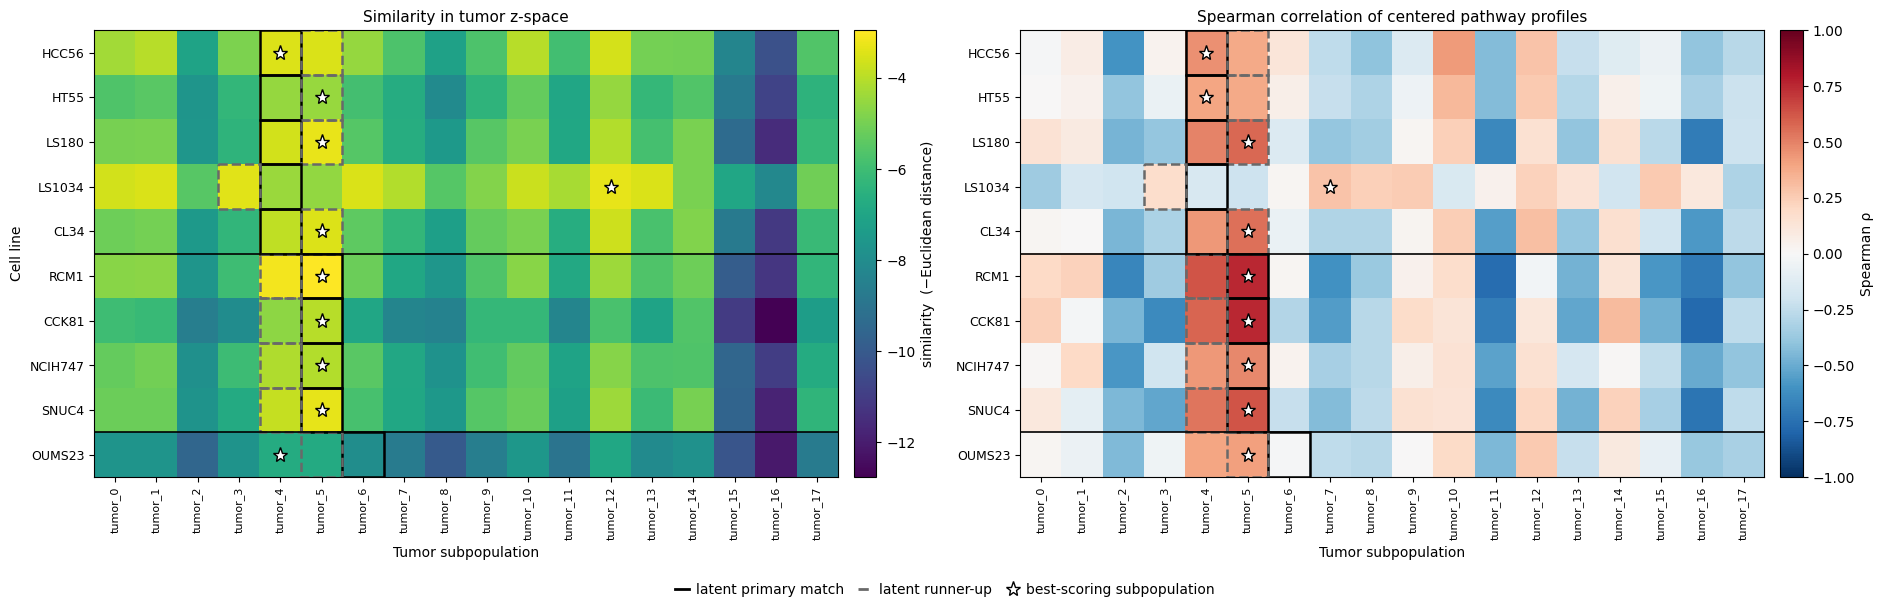

In [48]:
# Permutation null for the rank test.
# Shuffling the tumor subpopulation vectors leaves each line's multiset of
# similarities unchanged, so the null rank of a randomly assigned subpop is
# uniform over 1..n_subpops; this is sampled directly and is exact.
def permutation_null(sim, primary_map, n_perm=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    values = sim.reindex(index=line_labels).to_numpy(float)
    primary_col = np.array([sim.columns.get_loc(str(primary_map[l])) for l in line_labels])
    order = np.argsort(-values, axis=1)
    rank_of = np.empty_like(order)
    rank_of[np.arange(values.shape[0])[:, None], order] = np.arange(values.shape[1])[None, :]
    observed = rank_of[np.arange(values.shape[0]), primary_col] + 1
    null = rng.integers(1, values.shape[1] + 1, size=(n_perm, len(line_labels)))
    return observed, null


null_frames = []
for method in rank_readouts["method"].unique():
    if method.startswith("uncentered_spearman"):
        source = ("raw_spearman", all_pathways)
    elif method.startswith("z_dist"):
        source = ("z_dist", PATHWAY_SETS[method.split("| ")[1]])
    else:
        source = ("centered_spearman", PATHWAY_SETS[method.split("| ")[1]])
    metric, columns = source
    line_matrix = {
        "raw_spearman": cell_line_group_scores,
        "z_dist": cell_line_group_z,
        "centered_spearman": cell_line_group_c,
    }[metric]
    tumor_matrix = {
        "raw_spearman": tumor_group_scores,
        "z_dist": tumor_group_z,
        "centered_spearman": tumor_group_c,
    }[metric]
    sim = similarity_matrix(line_matrix, tumor_matrix, columns, "spearman" if metric != "z_dist" else "z_dist")
    observed, null = permutation_null(sim, line_matches["primary_match"])
    null_medians = np.median(null, axis=1)
    null_top3 = (null <= 3).mean()
    p_value = float((null_medians <= np.median(observed)).mean())
    null_frames.append({
        "method": method,
        "observed_median_rank": float(np.median(observed)),
        "null_median_rank_mean": float(null_medians.mean()),
        "null_median_rank_q05": float(np.quantile(null_medians, 0.05)),
        "observed_top1_rate": float((observed == 1).mean()),
        "null_top1_rate": 1.0 / len(tumor_labels),
        "observed_top3_rate": float((observed <= 3).mean()),
        "null_top3_rate": float(null_top3),
        "p_median_rank": p_value,
    })

null_summary = pd.DataFrame(null_frames).sort_values("observed_median_rank")
display(null_summary.round(3))

# Figure: pathway-profile similarity between each cell line and each tumor subpopulation.
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

plot_methods = [
    method for method in ["z_dist | tumor_sig", "centered_spearman | tumor_sig"]
    if method in rank_readouts["method"].unique()
]
if not plot_methods:
    plot_methods = rank_readouts["method"].unique()[:2].tolist()

row_order = LINE_ORDER

fig, axes = plt.subplots(
    ncols=len(plot_methods),
    figsize=(9.5 * len(plot_methods), 5.8),
    squeeze=False,
)
for ax, method in zip(axes[0], plot_methods):
    use_z = method.startswith("z_dist")
    columns = PATHWAY_SETS[method.split("| ")[1]]
    line_matrix = cell_line_group_z if use_z else cell_line_group_c
    tumor_matrix = tumor_group_z if use_z else tumor_group_c
    similarity = similarity_matrix(
        line_matrix, tumor_matrix, columns, "z_dist" if use_z else "spearman"
    ).reindex(index=row_order, columns=tumor_labels)

    if use_z:
        image = ax.imshow(
            similarity.to_numpy(float), aspect="auto",
            cmap="viridis", interpolation="nearest",
        )
        title = "Similarity in tumor z-space"
        colorbar_label = "similarity  (−Euclidean distance)"
    else:
        image = ax.imshow(
            similarity.to_numpy(float), aspect="auto",
            cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest",
        )
        title = "Spearman correlation of centered pathway profiles"
        colorbar_label = "Spearman ρ"

    ax.set_xticks(np.arange(len(tumor_labels)))
    ax.set_xticklabels(tumor_labels, rotation=90, fontsize=8)
    ax.set_yticks(np.arange(len(row_order)))
    ax.set_yticklabels(row_order, fontsize=9)
    ax.set_xlabel("Tumor subpopulation")
    ax.set_title(title, fontsize=11)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.02).set_label(colorbar_label)

    for y, cell_line in enumerate(row_order):
        for group, color, linestyle in [
            (str(line_matches.loc[cell_line, "primary_match"]), "black", "-"),
            (str(line_matches.loc[cell_line, "second_match"]), "dimgray", "--"),
        ]:
            if group in tumor_labels:
                x = tumor_labels.index(group)
                ax.add_patch(Rectangle(
                    (x - 0.5, y - 0.5), 1, 1, fill=False,
                    edgecolor=color, linewidth=1.8, linestyle=linestyle,
                ))
        best = similarity.loc[cell_line].idxmax()
        ax.plot(
            tumor_labels.index(best), y, marker="*", color="white",
            markeredgecolor="black", markersize=11, zorder=5,
        )

    previous_primary = None
    for y, cell_line in enumerate(row_order):
        primary = str(line_matches.loc[cell_line, "primary_match"])
        if previous_primary is not None and primary != previous_primary:
            ax.axhline(y - 0.5, color="black", linewidth=1.2)
        previous_primary = primary

axes[0, 0].set_ylabel("Cell line")
fig.legend(
    handles=[
        Line2D([0], [0], color="black", lw=2, label="latent primary match"),
        Line2D([0], [0], color="dimgray", lw=2, linestyle="--", label="latent runner-up"),
        Line2D([0], [0], marker="*", color="white", markeredgecolor="black",
               linestyle="", markersize=11, label="best-scoring subpopulation"),
    ],
    loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.05),
)
plt.tight_layout()
fig.savefig(FIG_DIR / "pathway_profile_similarity.png", dpi=300, bbox_inches="tight")
plt.show()

# Metadata views (donor/sample + QC)